In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Платформа АБ-тестов и система сплитования

## Общий пайплайн АБ-теста

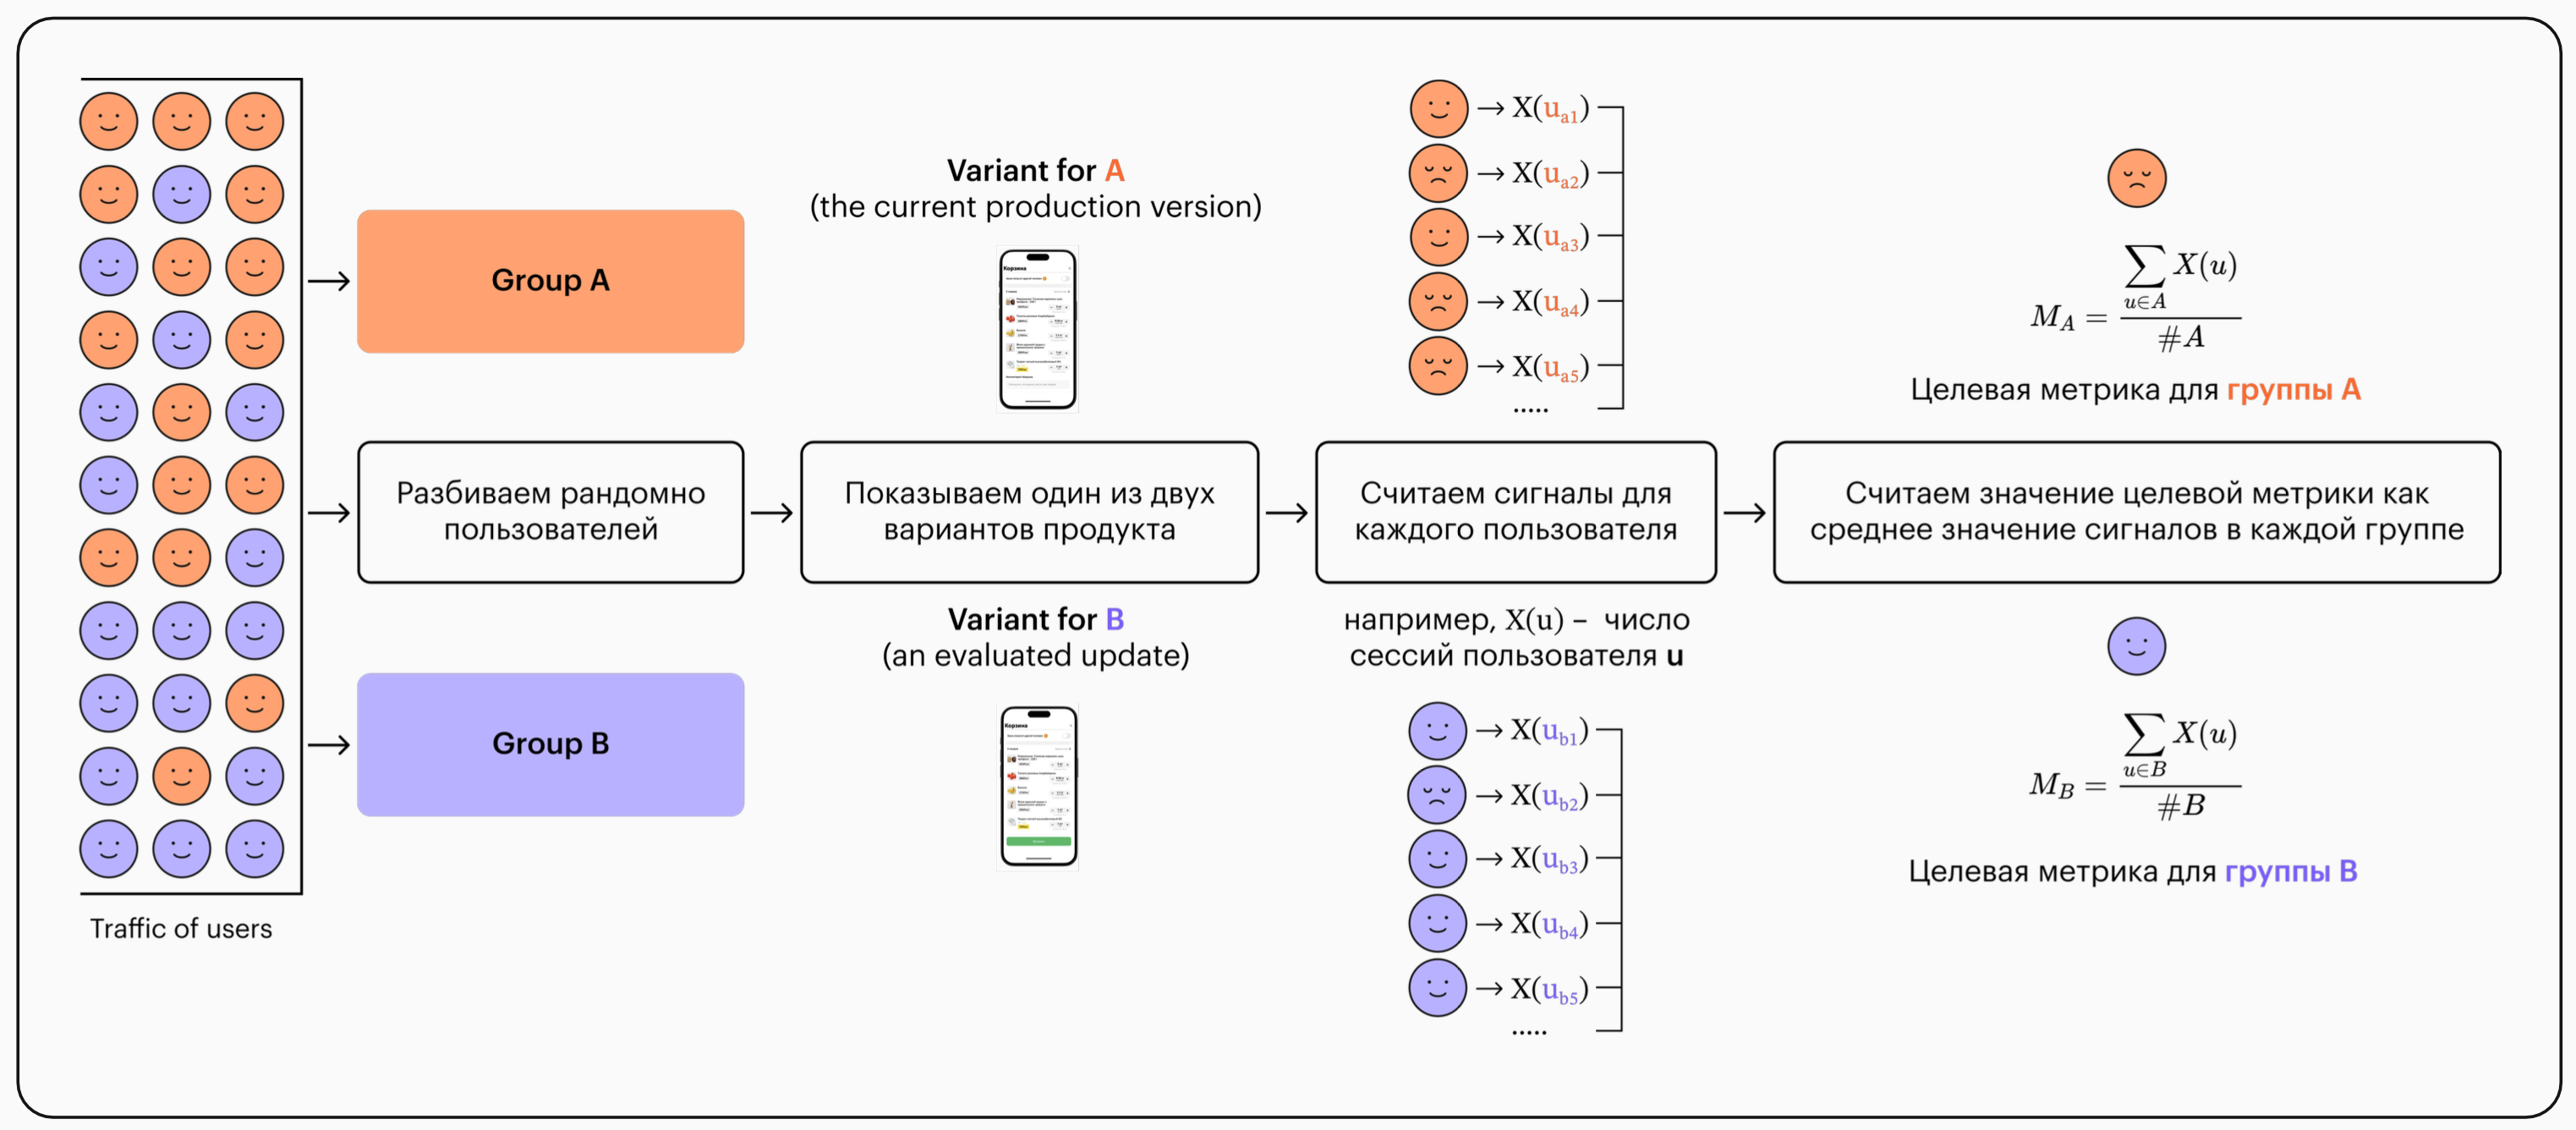

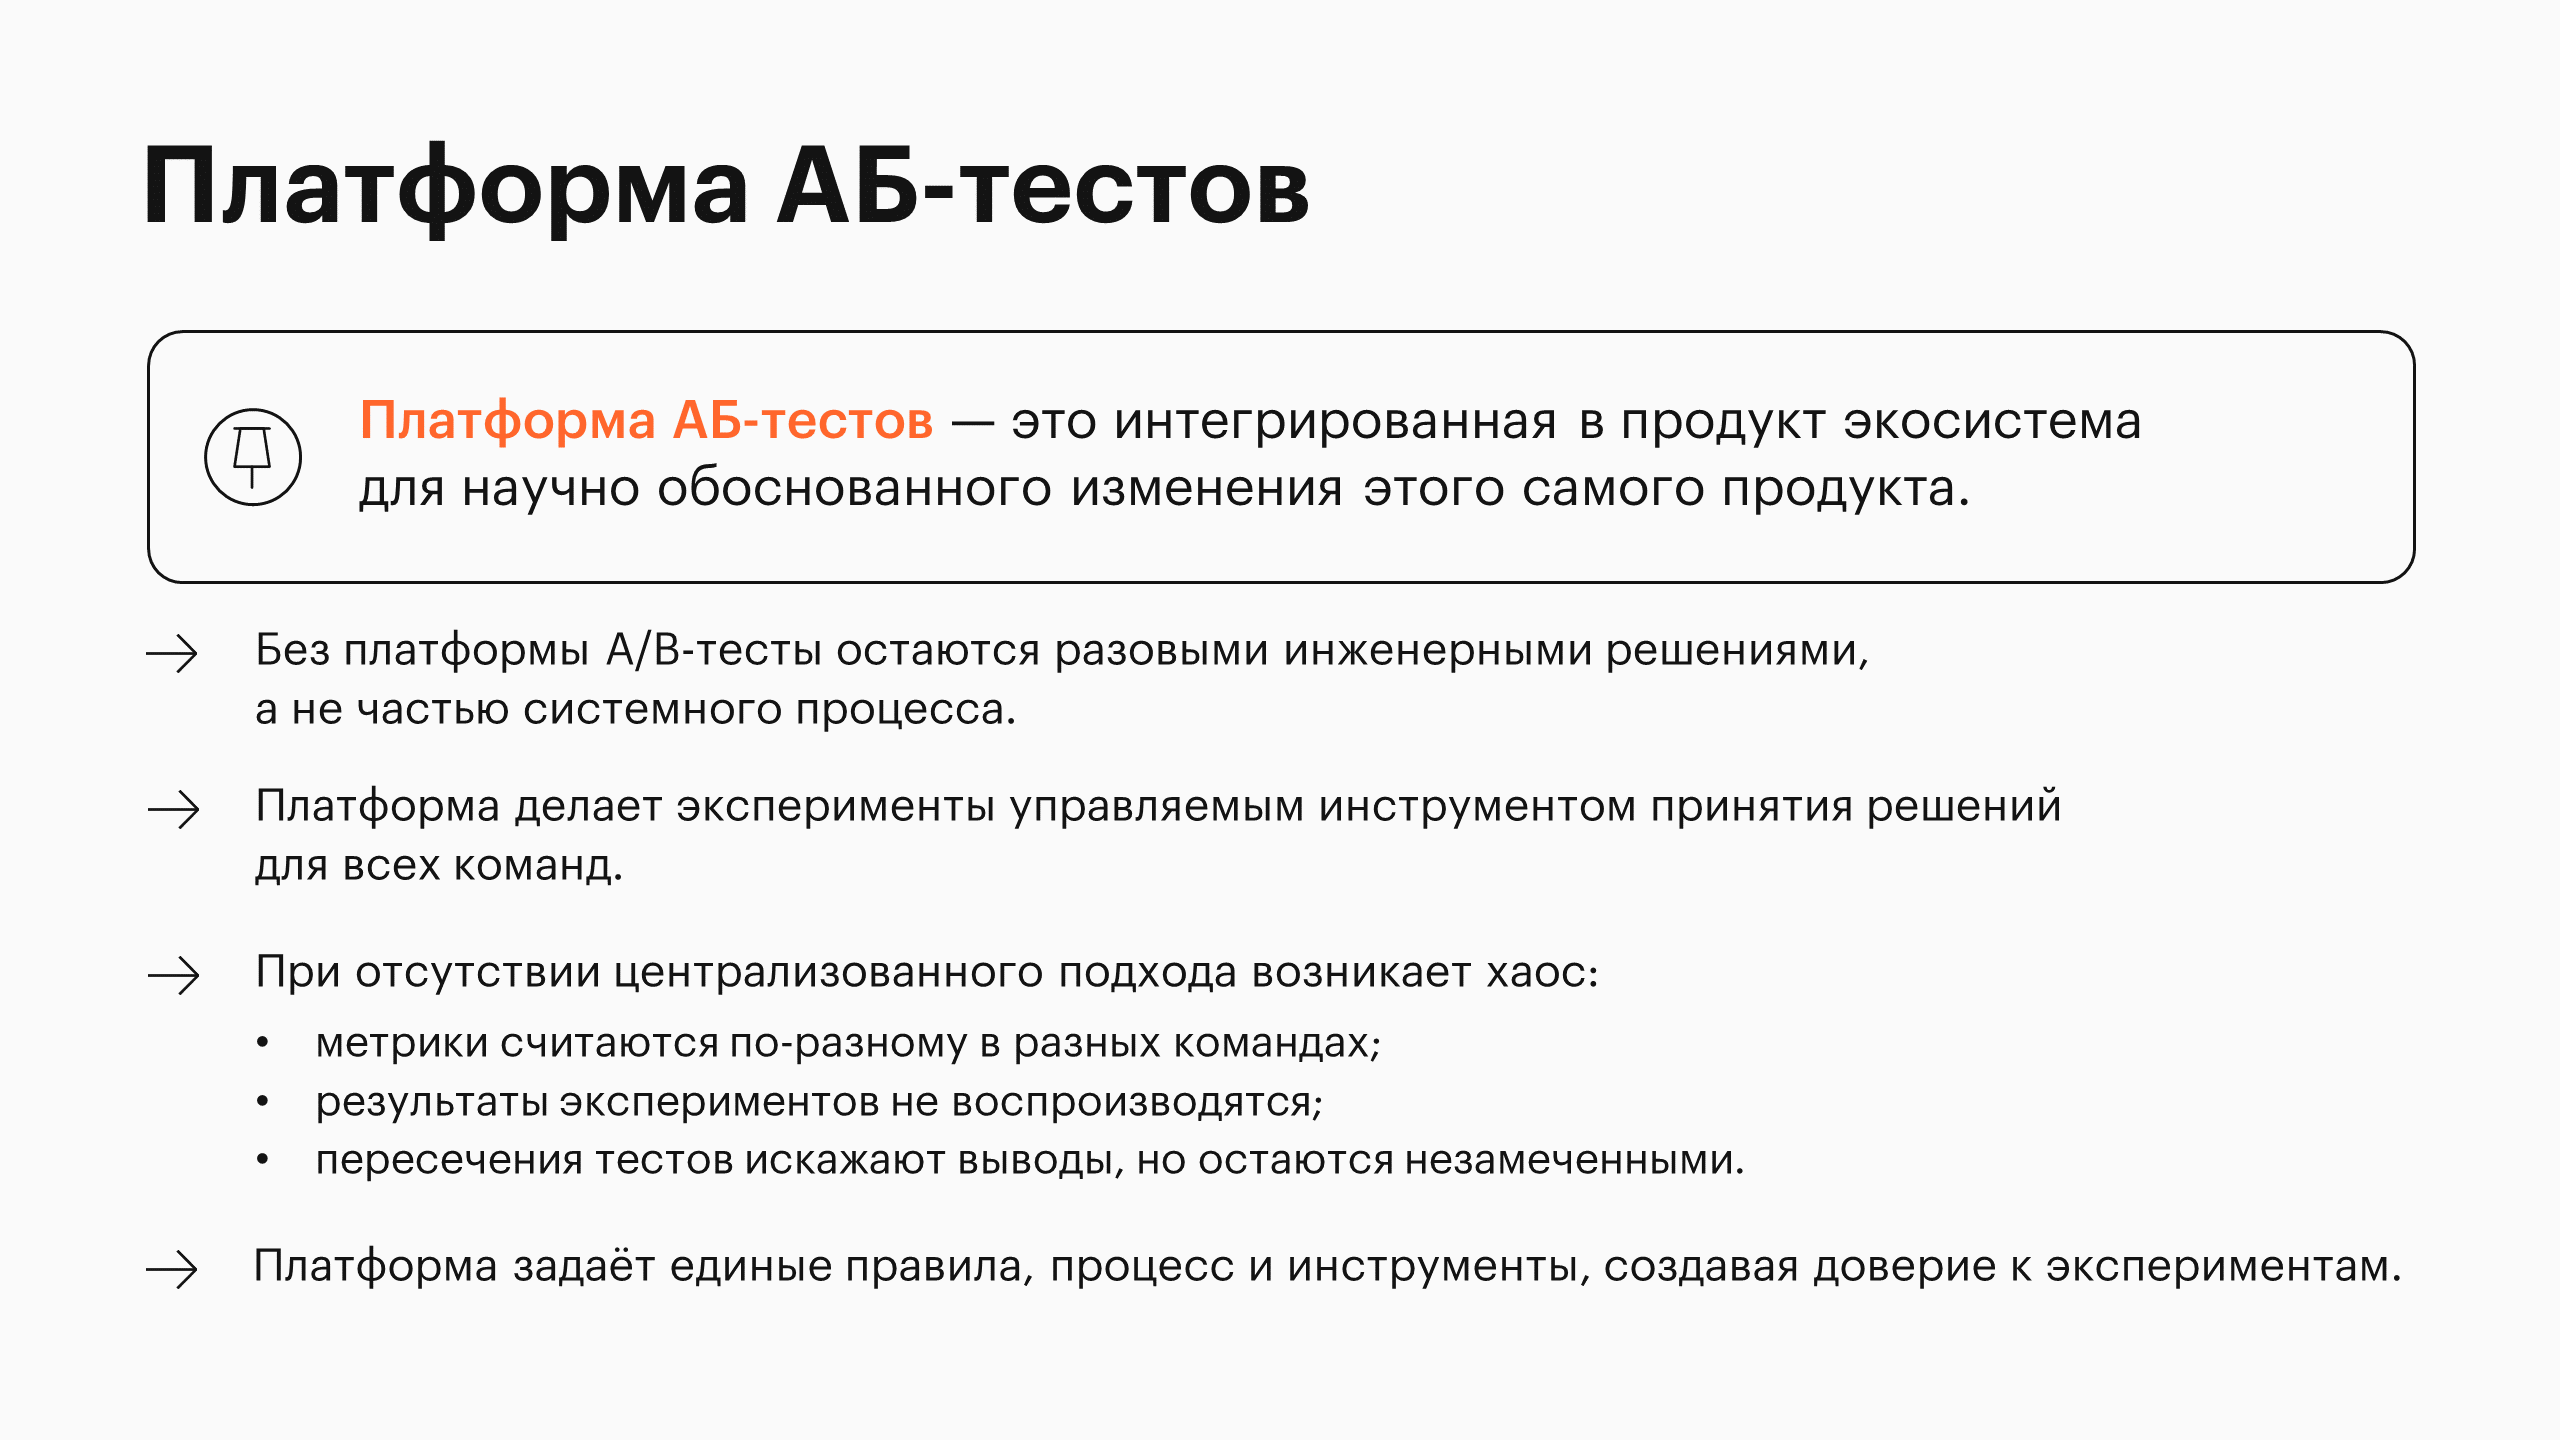

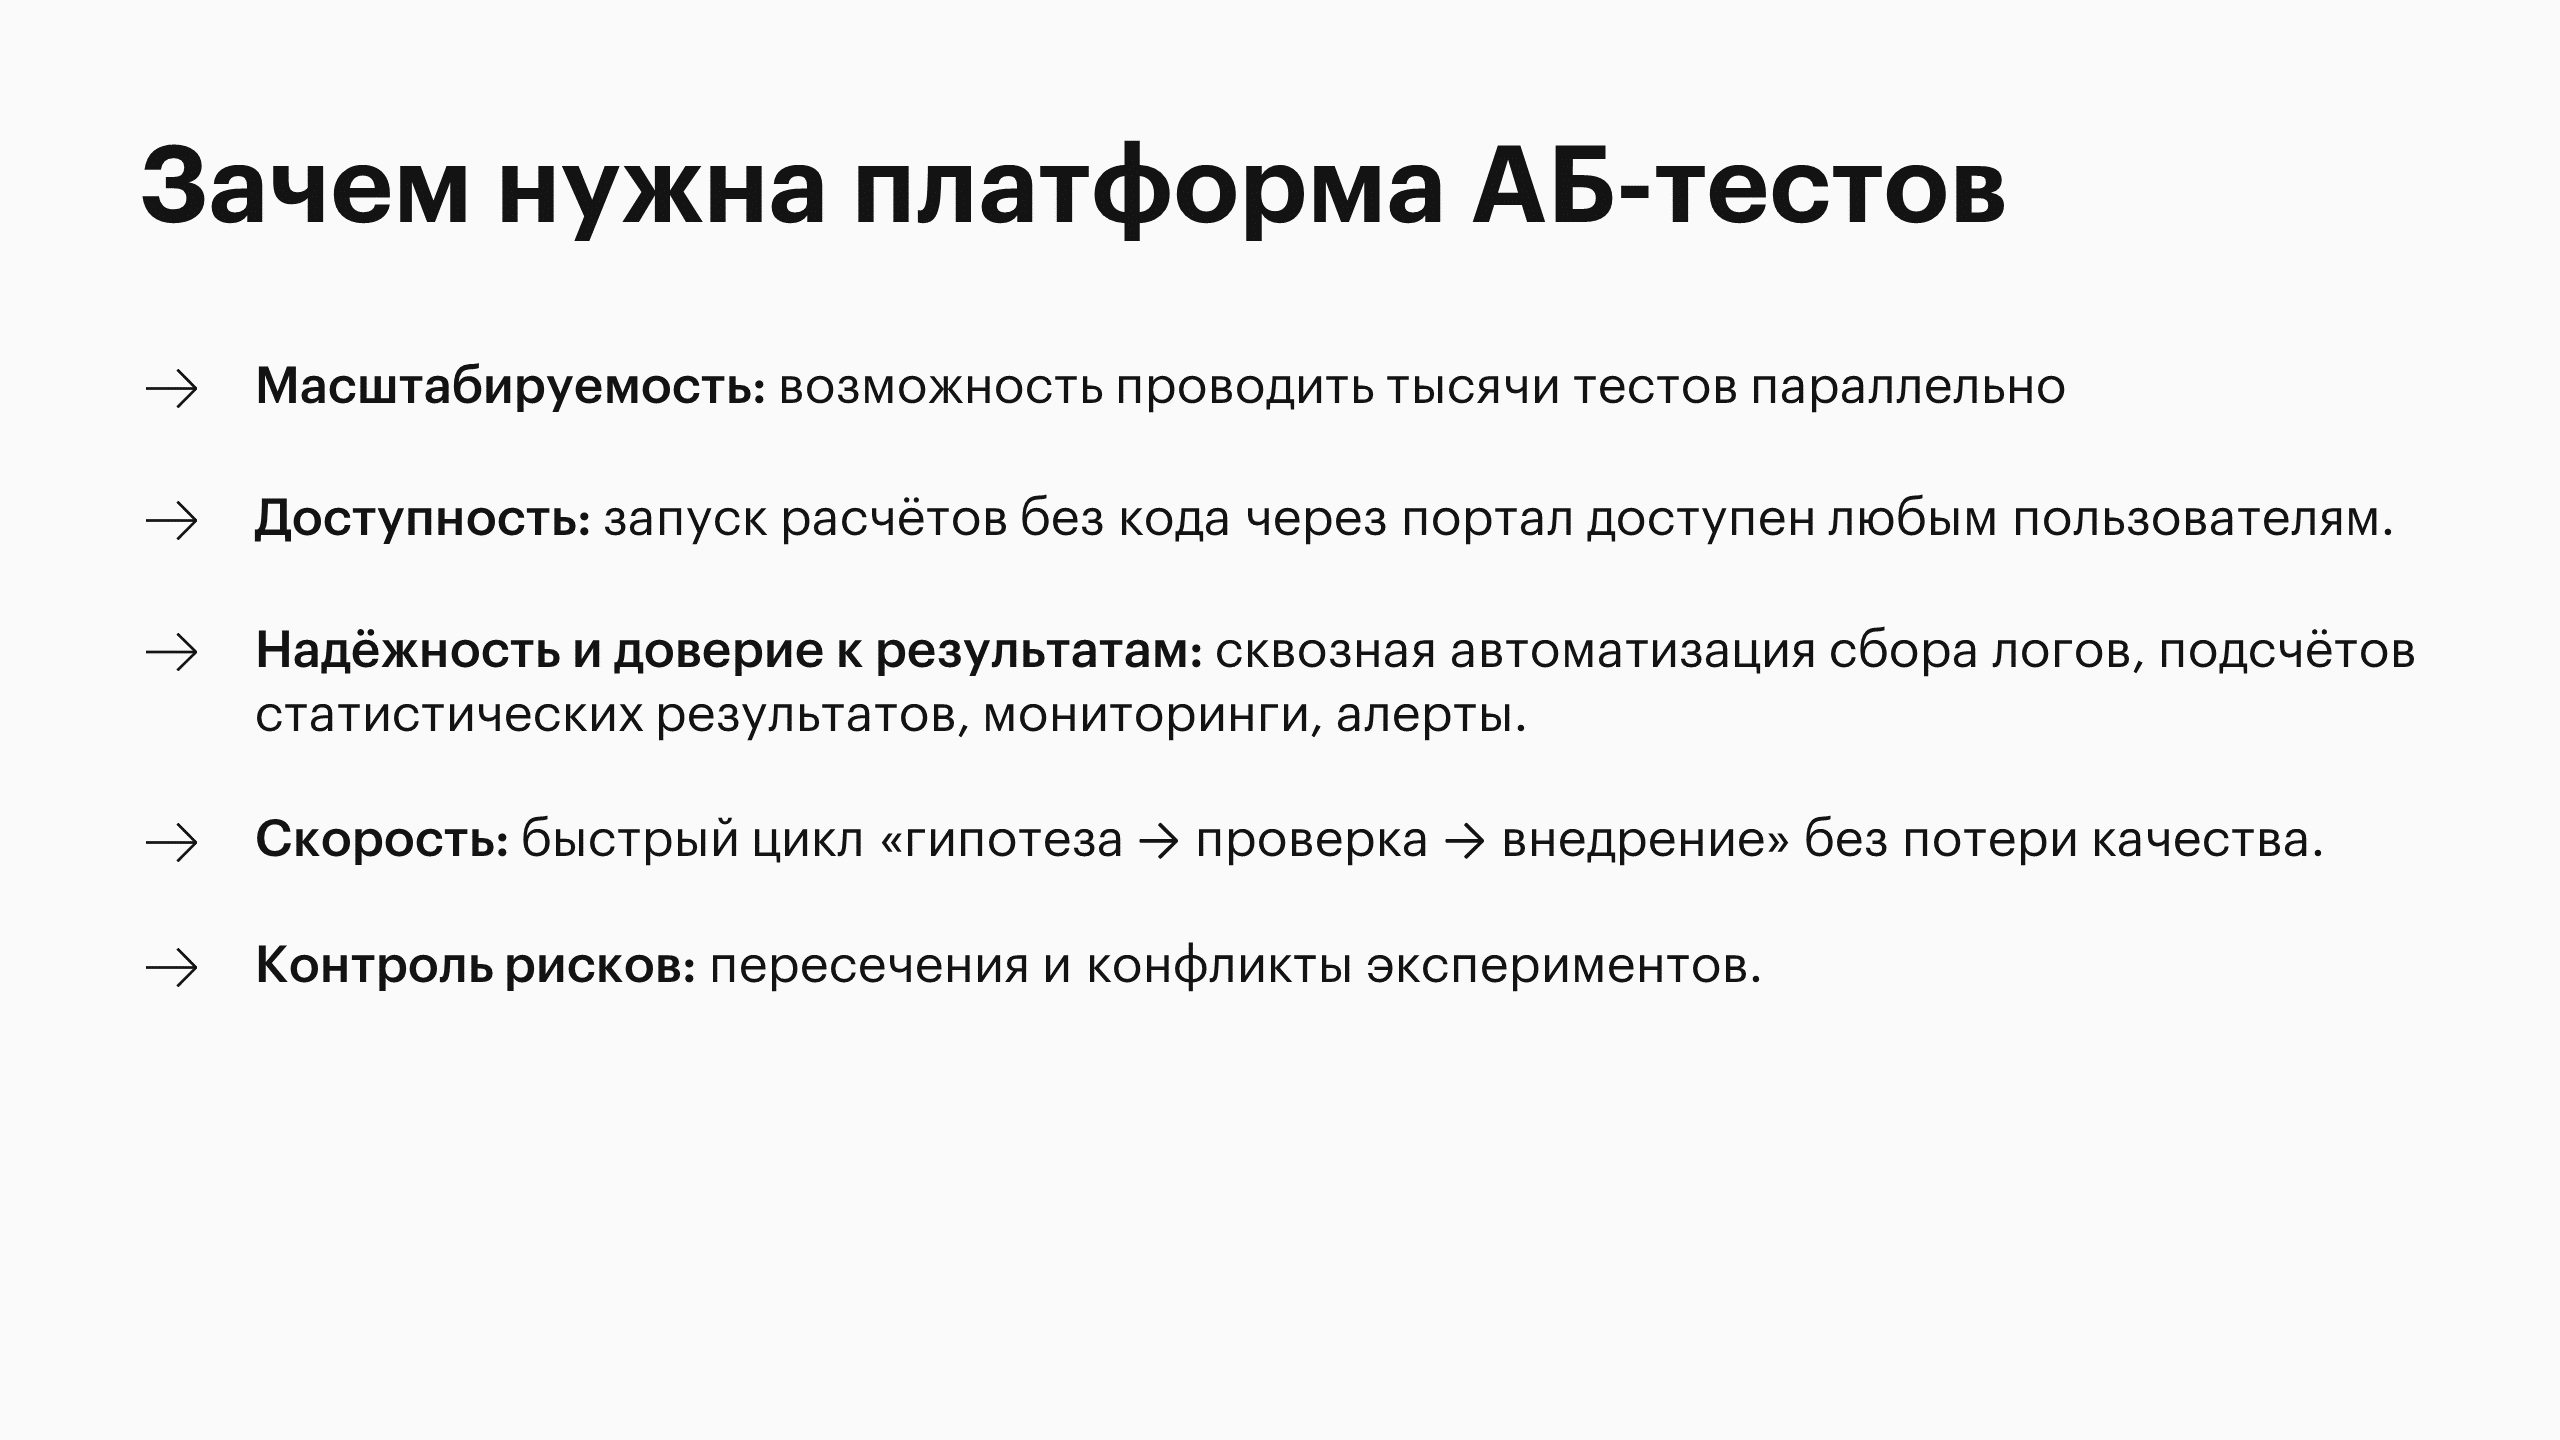

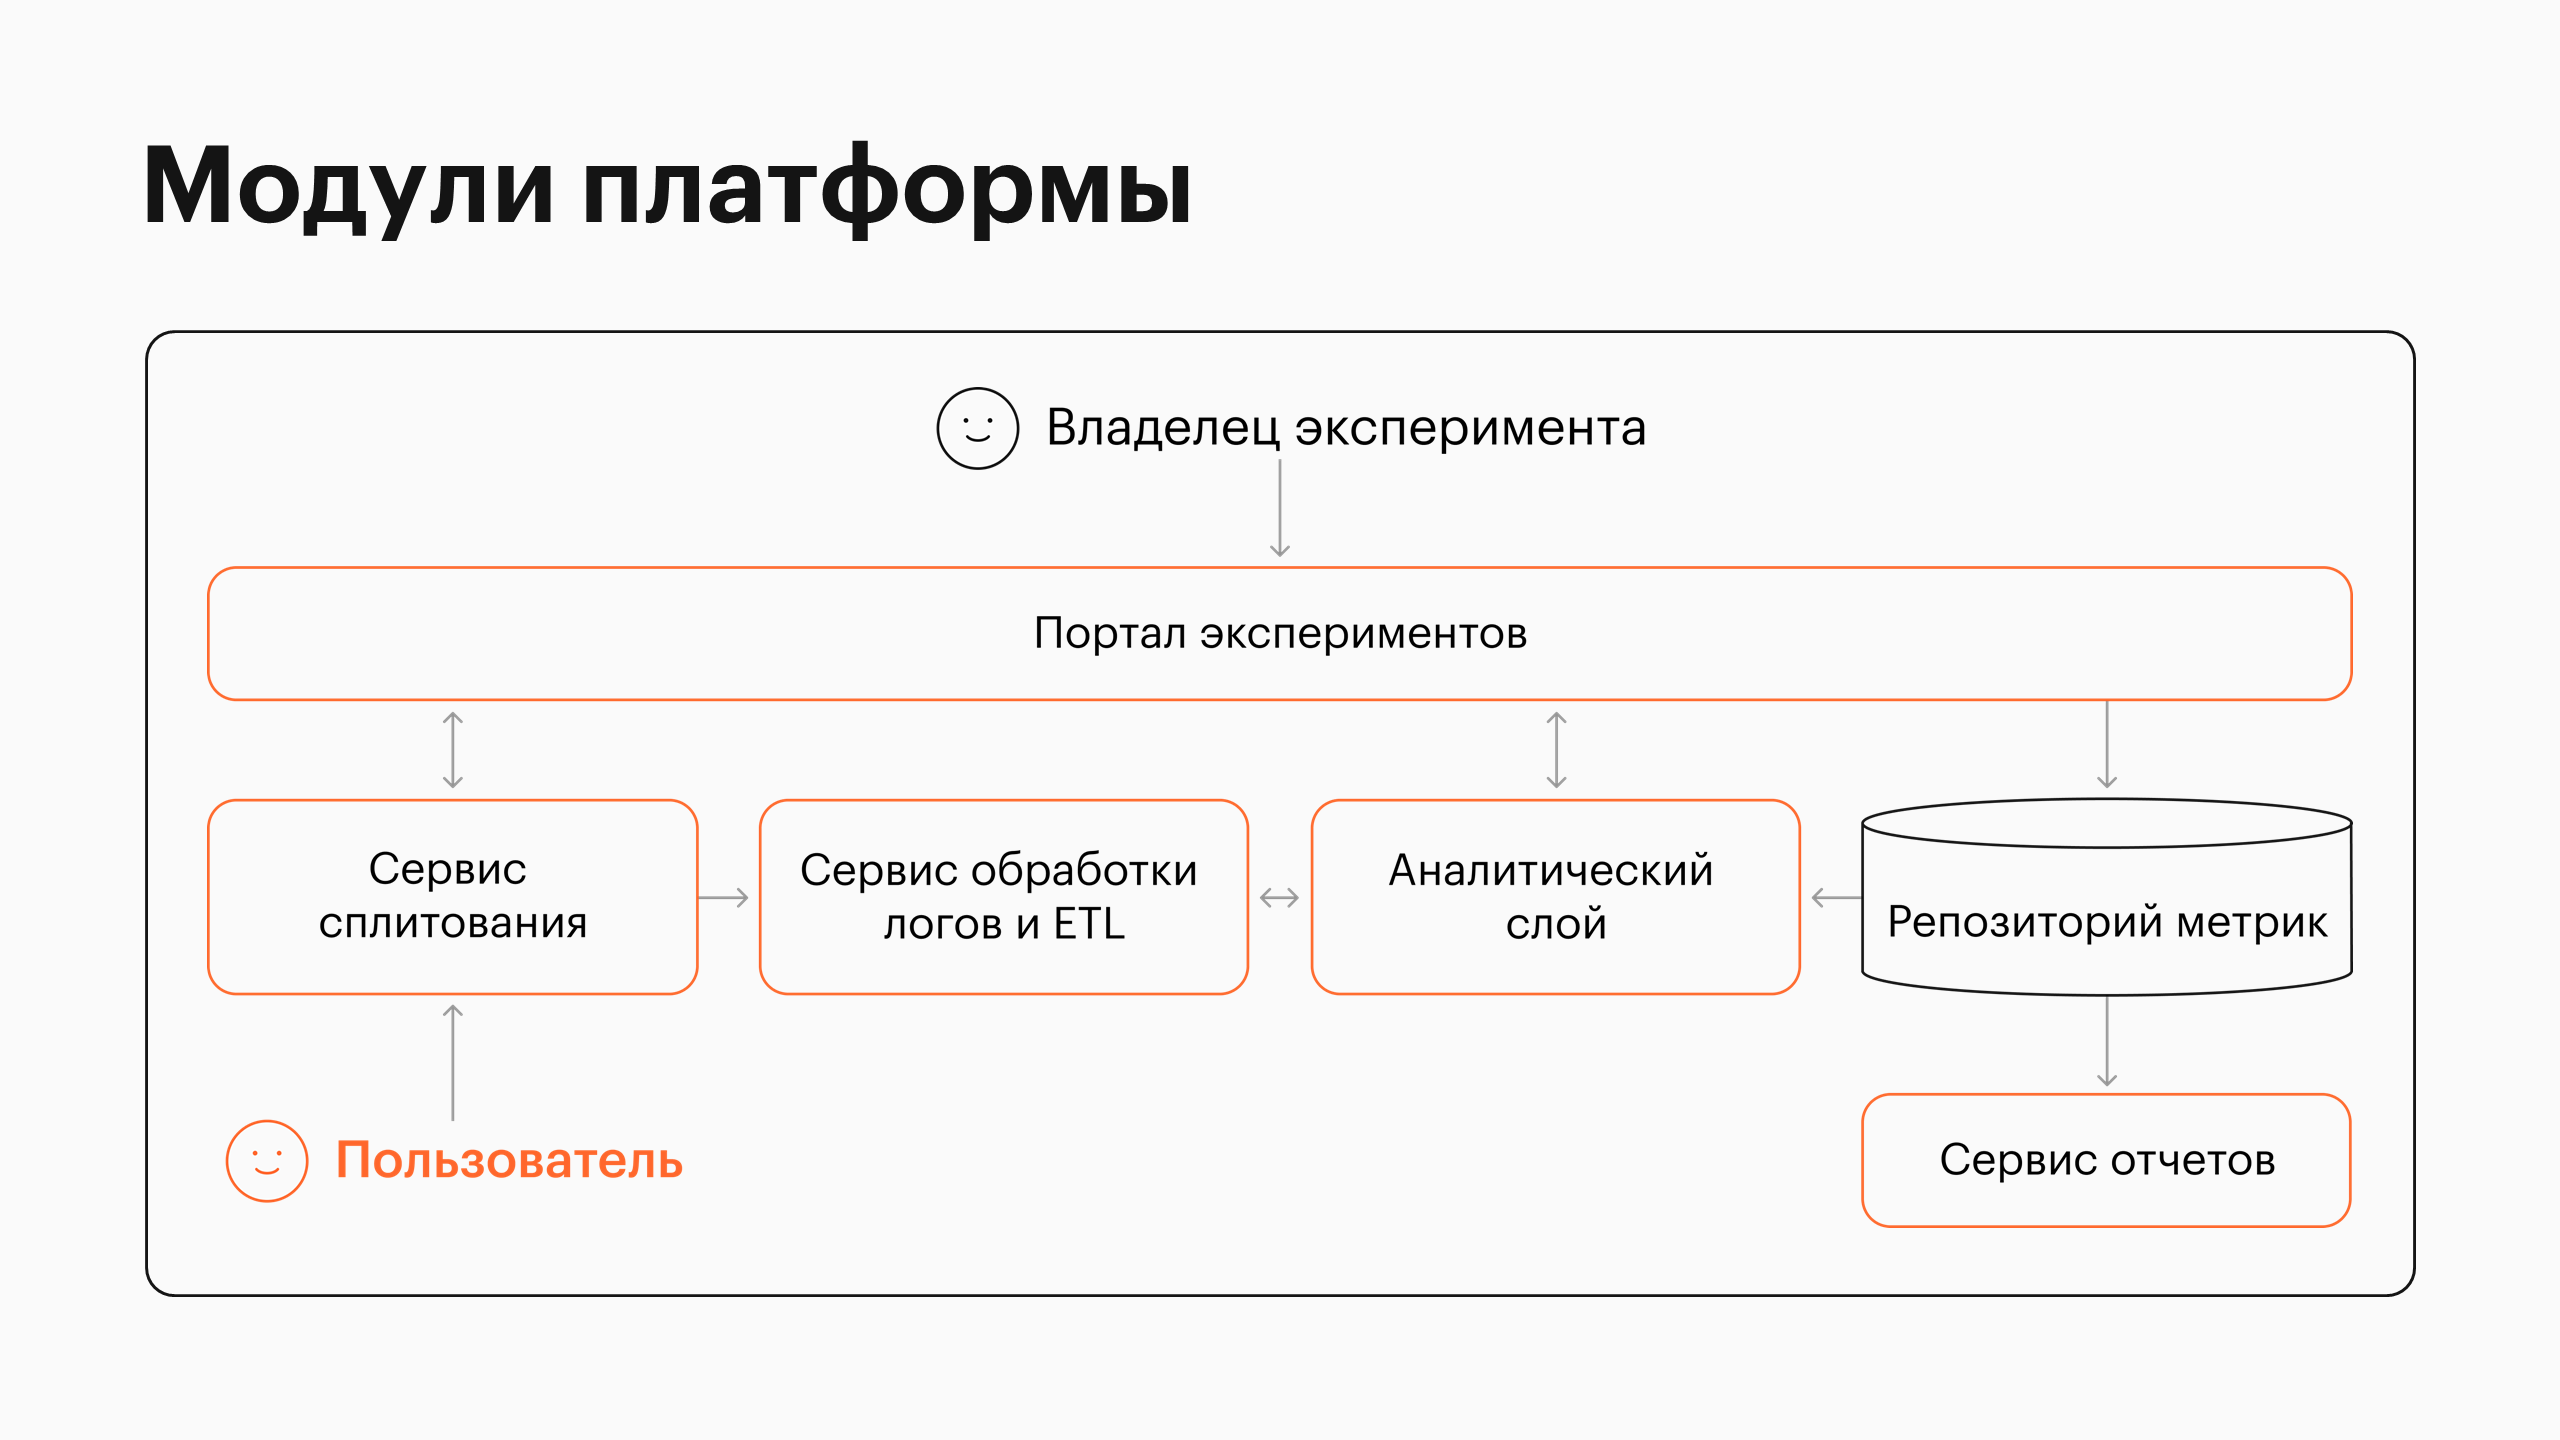

## Сплит-система и АА-тесты

**Сплит-система** — это система автоматизированного разделения трафика клиентов на экспериментальные группы.

Важно, чтобы разделение было **случайным**, иначе разницу в значениях метрик между экспериментальными группами нельзя будет атрибуцировать к
ёразнице, полученной из-за наличия экспериментального воздействия в тестовой группе.

Давайте эту проблему разберём на примере, для этого нам надо вспомнить, что такое А/А-тесты и для чего они нужны.


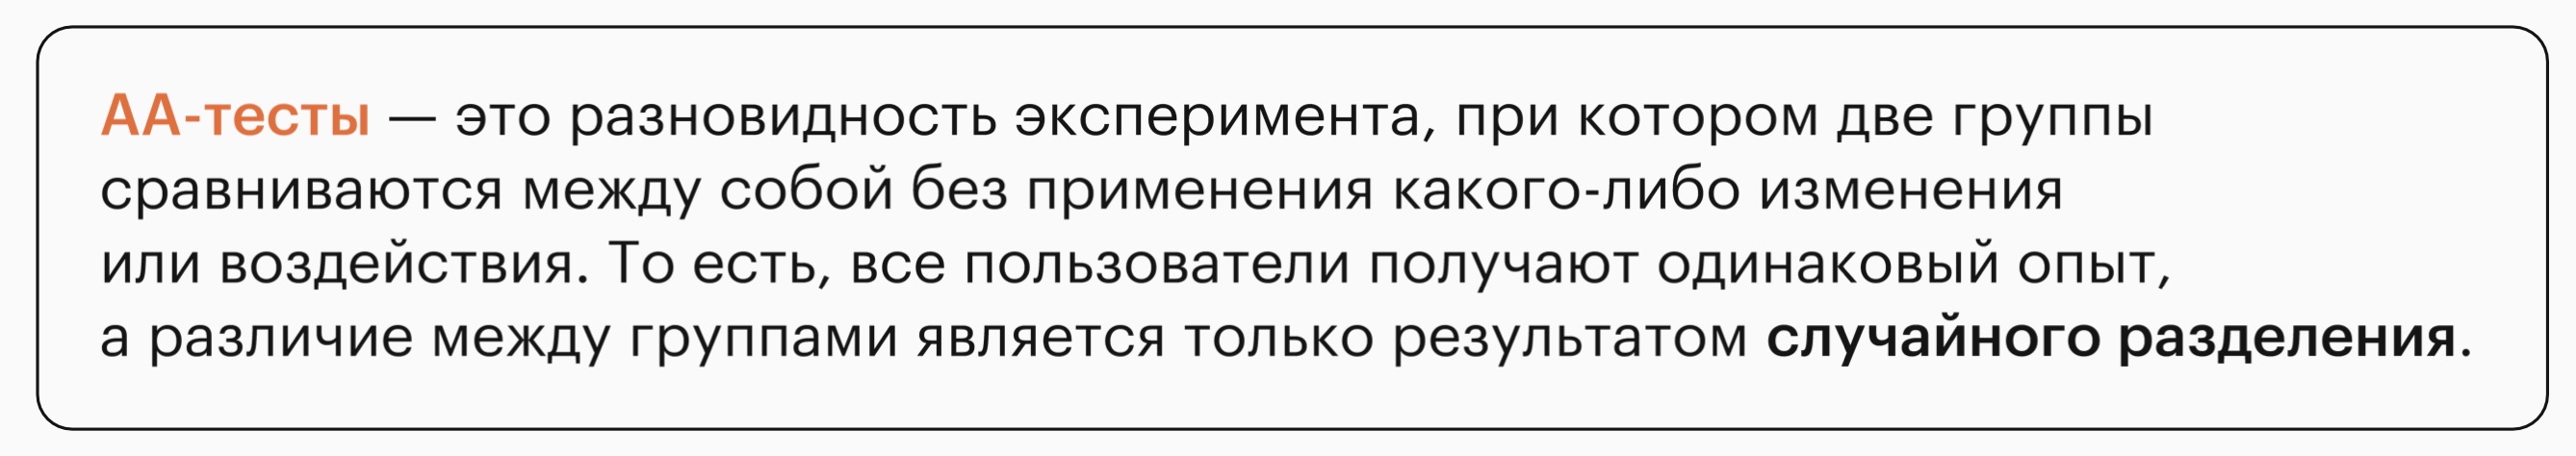

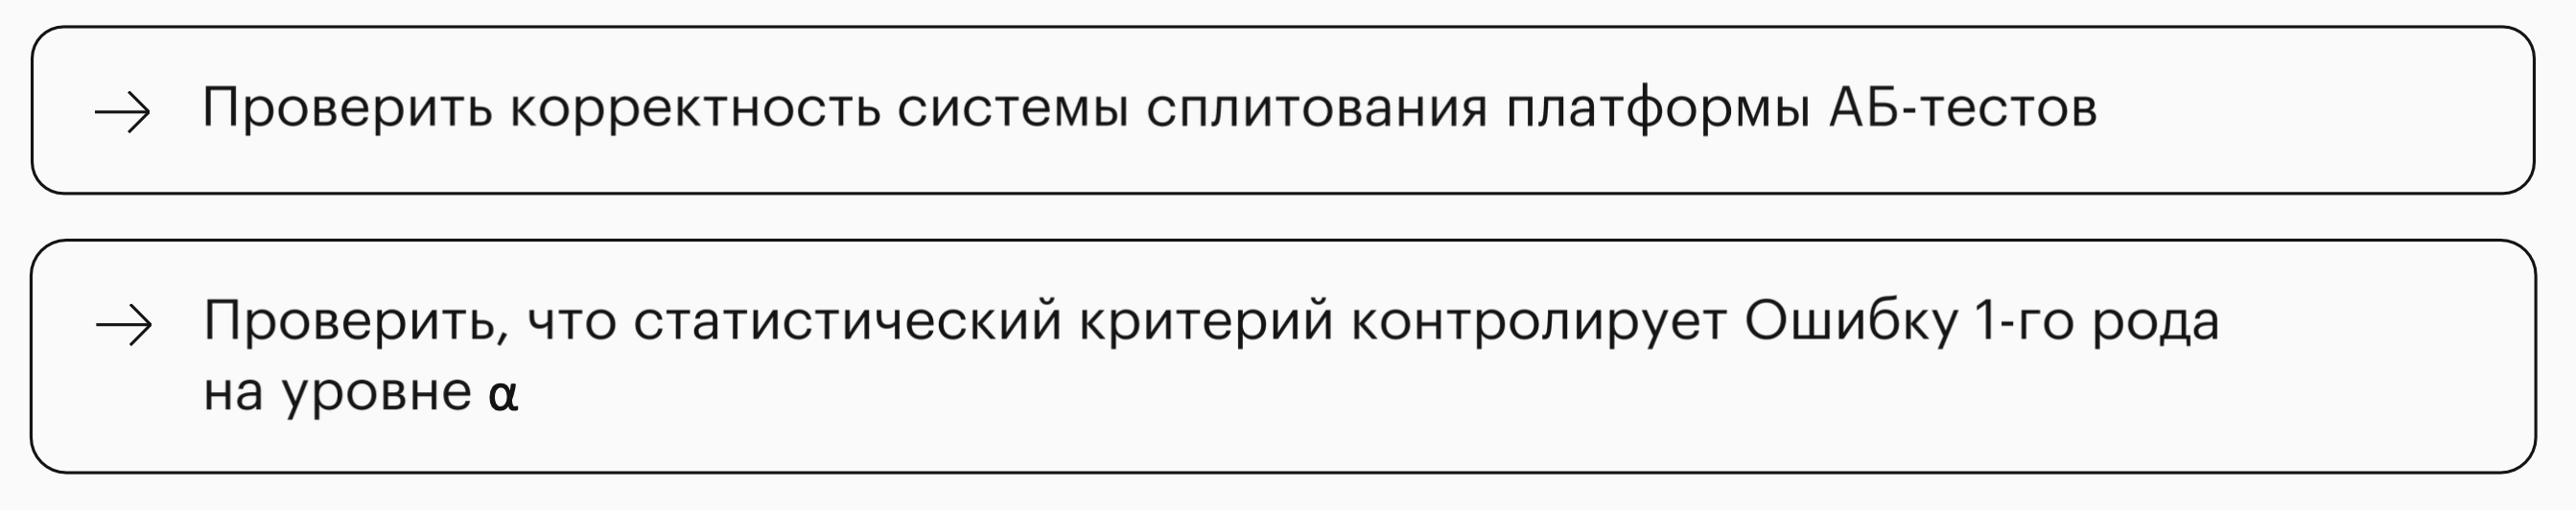

В **А/А-тестах** для проверки платформы экспериментов мы прогоняем всех пользователей через разбиение на фейк-группы, которые на самом деле ничем не отличаются, в соответствии с правилами сплит-системы.

**Затем проверяются результаты**: множество непересекающихся фейк-групп не должны показывать *систематического* статистически значимого отличия друг от друга.

**Пример проверки сплит-системы с помощью А/A-теста**

При *сплитовании* можем исходить из значения **идентификатора**.

Импортируем датасет с информацией об *идентификаторах* клиентов, а также об их *клиентском GMV*.

In [ ]:
df_aa = pd.read_excel('aa_test_for_hash.xlsx')
df_aa['is_user'] = 1

print(len(df_aa))
df_aa.head()

31304


,id_client,amt_pay,is_user
0,2033218,2040,1
1,2072551,3246,1
2,2081474,2041,1
3,2023747,2475,1
4,2082766,715,1


In [ ]:
# Отбор сигналов для метрик
def get_signals(df, num_flg, denom_flg):
    numerator = df[num_flg].values
    denominator = df[denom_flg].values

    numerator = numerator[denominator>0]
    denominator = denominator[denominator>0]
    return numerator, denominator


# Считает результаты эксперимента для t-теста
def get_stats_res(num_t, denom_t, num_c, denom_c):
  t_metr = np.sum(num_t) / np.sum(denom_t)
  c_metr = np.sum(num_c) / np.sum(denom_c)
  diff = t_metr - c_metr
  rel_diff = diff / c_metr

  t_stat, pval = stats.ttest_ind(num_t, num_c)

  return t_metr, c_metr, diff, rel_diff, t_stat, pval

Разделим наблюдения на группы в соответствии с чётностью идентификатора.

 - Чётные условно обозначим за $0$ (или $A$), то есть контрольная группа
 - Нечётные условно обозначим за $1$ (или $B$), то есть тестовая/пилотная группа

In [ ]:
df_aa['group_last_id'] = df_aa['id_client'] % 2

df_aa.head()

,id_client,amt_pay,is_user,group_last_id
0,2033218,2040,1,0
1,2072551,3246,1,1
2,2081474,2041,1,0
3,2023747,2475,1,1
4,2082766,715,1,0


In [ ]:
metric_dict = {
    'GMV на пользователя': ['amt_pay', 'is_user']
}

In [ ]:
df_c = df_aa[df_aa['group_last_id']==0].copy()
df_t = df_aa[df_aa['group_last_id']==1].copy()

In [ ]:
for metric in metric_dict:
  num_flg, denom_flg = metric_dict[metric]

  num_t, denom_t = get_signals(df_t, num_flg, denom_flg)
  num_c, denom_c = get_signals(df_c, num_flg, denom_flg)

  t_metr, c_metr, diff, rel_diff, t_stat, pval = get_stats_res(num_t, denom_t, num_c, denom_c)

  print(metric)
  print(f'\tЗначение в тесте: {round(t_metr, 2)}')
  print(f'\tЗначение в контроле: {round(c_metr, 2)}')
  print(f'\tАбсолютная разница: {round(diff, 3)}')
  print(f'\tОтносительная разница: {round(100*rel_diff, 2)}%')
  print(f'\tТ-статистика: {round(t_stat, 4)}\tp-value: {round(pval, 4)}')
  print()

GMV на пользователя
	Значение в тесте: 2692.86
	Значение в контроле: 3246.73
	Абсолютная разница: -553.869
	Относительная разница: -17.06%
	Т-статистика: -32.574	p-value: 0.0



Ну или же рассчитаем средние и дисперсии в каждой группе и сравним средние в двух группах с помощью Z-критерия.

In [ ]:
amt_pay_0 = df_c['amt_pay'].values  # Наблюдения в контроле
amt_pay_1 = df_t['amt_pay'].values  # Наблюдения в тесте

m_0, m_1 = amt_pay_0.mean(), amt_pay_1.mean()

var_0, var_1 = amt_pay_0.var(), amt_pay_1.var()

n_0, n_1 = len(amt_pay_0), len(amt_pay_1)

z_stat = (m_1 - m_0) / (var_0/n_0 + var_1/n_1)**.5

print("В группе 0:")
print("\tСредний платёж: ", round(m_0, 2))
print("\tДисперсия: ", round(var_0, 2))
print("\tКол-во наблюдений: ", n_0)
print()
print("В группе 1:")
print("\tСредний платёж: ", round(m_1, 2))
print("\tДисперсия: ", round(var_1, 2))
print("\tКол-во наблюдений: ", n_1)
print()
print("Значение Z-статистики: ", round(z_stat, 3))

В группе 0:
	Средний платёж:  3246.73
	Дисперсия:  3014557.81
	Кол-во наблюдений:  15344

В группе 1:
	Средний платёж:  2692.86
	Дисперсия:  1537704.89
	Кол-во наблюдений:  15960

Значение Z-статистики:  -32.368


**Вавод**: при сплитовании пользователей по принципу (не)чётности их идентификаторов мы получаем статзначимые различия.

Выясним, можно ли верить такому критерию сплитования

### Сплитование по идентификатору

Просимулируем разбиение потока наших пользователей через платформу экспериментов.

Разобьём пользователей на равные батчи для сравнения в 1000 непересекающихся А/А-тестов.

In [ ]:
n_batch = 1000

# Перемешаем
df_c = df_c.sample(frac=1).reset_index(drop=True).copy()
df_t = df_t.sample(frac=1).reset_index(drop=True).copy()

# Режем на 1000 почти равных частей
idx_c_splits = np.array_split(np.arange(len(df_c)), n_batch)
idx_t_splits = np.array_split(np.arange(len(df_t)), n_batch)

parts_c = [df_c.iloc[idx] for idx in idx_c_splits]
parts_t = [df_t.iloc[idx] for idx in idx_t_splits]

In [ ]:
# Второй батч в контрольной группе
print(len(parts_c[1]))
parts_c[1].head()

16


,id_client,amt_pay,is_user,group_last_id
16,2054620,6053,1,0
17,2092764,1132,1,0
18,2053958,1692,1,0
19,2054746,3040,1,0
20,2091268,1931,1,0


In [ ]:
# Второй батч в тестовой группе
print(len(parts_t[1]))
parts_t[1].head()

16


,id_client,amt_pay,is_user,group_last_id
16,2033993,821,1,1
17,2022539,2525,1,1
18,2063625,2595,1,1
19,2031085,4592,1,1
20,2064939,4863,1,1


In [ ]:
alpha=0.05

p_vals = []
# Сравним батчи попарно и посчитаем FPR
for i in range(n_batch):
    a = parts_c[i]
    b = parts_t[i]

    num_t, denom_t = get_signals(a, 'amt_pay', 'is_user')
    num_c, denom_c = get_signals(b, 'amt_pay', 'is_user')
    _, _, _, _, _, pval = get_stats_res(num_t, denom_t, num_c, denom_c)
    p_vals.append(pval)


p_vals = np.array(p_vals)
fpr = sum(p_vals < alpha) / n_batch

'False Positive Rate: 14.8 %'

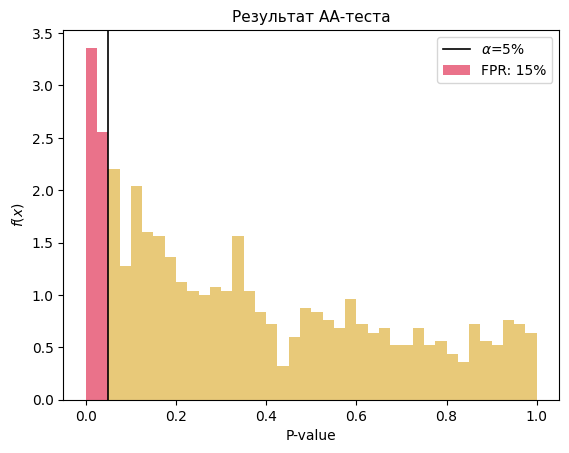

In [ ]:
cond = p_vals < 0.05
plt.axvline(0.05, color='black', linewidth=1.2, label=r'$\alpha$=5%')
plt.hist([p_vals[cond], p_vals[~cond]], bins=40, color=['crimson', 'goldenrod'], density=True,
        histtype='barstacked', label=[f'FPR: {round(100*fpr)}%', ''], alpha=0.6)
plt.title('Результат АА-теста', fontsize=11)
plt.xlabel('P-value', fontsize=10)
plt.ylabel('$f(x)$', fontsize=10)
plt.legend(loc=1, fontsize=10)


f'False Positive Rate: {round(100.0 * fpr, 2)} %'

**Вывод**

Получили системное смещение результатов при разбиении групп по (не)чётности идентификаторов.

Судя по всему, идентификаторы несут в себе информацию о клиенте с точки зрения кодировки.

Посмотрим, как зависит средний GMV от последней цифры идентификатора, то есть попытаемся раскрыть паттерн кодирования идентификатора.

In [ ]:
df_aa['r_s'] = df_aa['id_client'].astype(str).str[-1]

df_aa.head()

,id_client,amt_pay,is_user,group_last_id,r_s
0,2033218,2040,1,0,8
1,2072551,3246,1,1,1
2,2081474,2041,1,0,4
3,2023747,2475,1,1,7
4,2082766,715,1,0,6


In [ ]:
i_l = []
m_l = []
n_l = []

for i in sorted(df_aa['r_s'].unique()):
  i_l.append(i)

  # Число уникальных пользователей
  n = len(df_aa[df_aa['r_s']==i]['amt_pay'])
  n_l.append(n)

  # Значение метрики
  m = df_aa[df_aa['r_s']==i]['amt_pay'].mean()
  m_l.append(m)

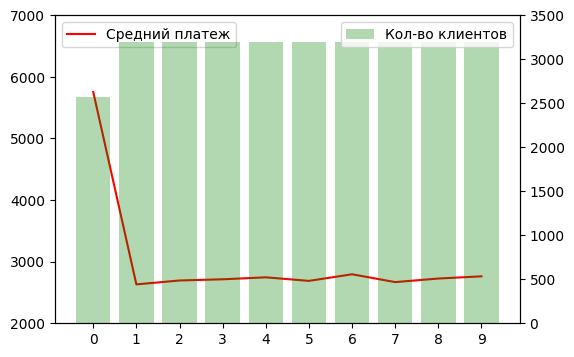

In [ ]:
plt.rcParams["figure.figsize"] = (6,4)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(i_l, m_l, color = 'red', label = 'Средний платеж')
ax2.bar(i_l, n_l, color = 'green', alpha = .3, label = 'Кол-во клиентов')
ax1.legend(loc = 'upper left')
ax2.legend(loc = 'upper right')
ax1.set_ylim([2000, 7000])
ax2.set_ylim([0, 3500])

plt.show()

**Вывод**

Нулём в качестве последнего символа кодируются клиенты из отдельного сегмента (возможно, лояльные или привлечённые каким-то определённым образом).

Поэтому не можем использовать в качестве сплит-системы просто принцип чётности.

Разберём, по какому принципу устроено сплитование в промышленных АБ-платформах.

### Хеширование идентификатора

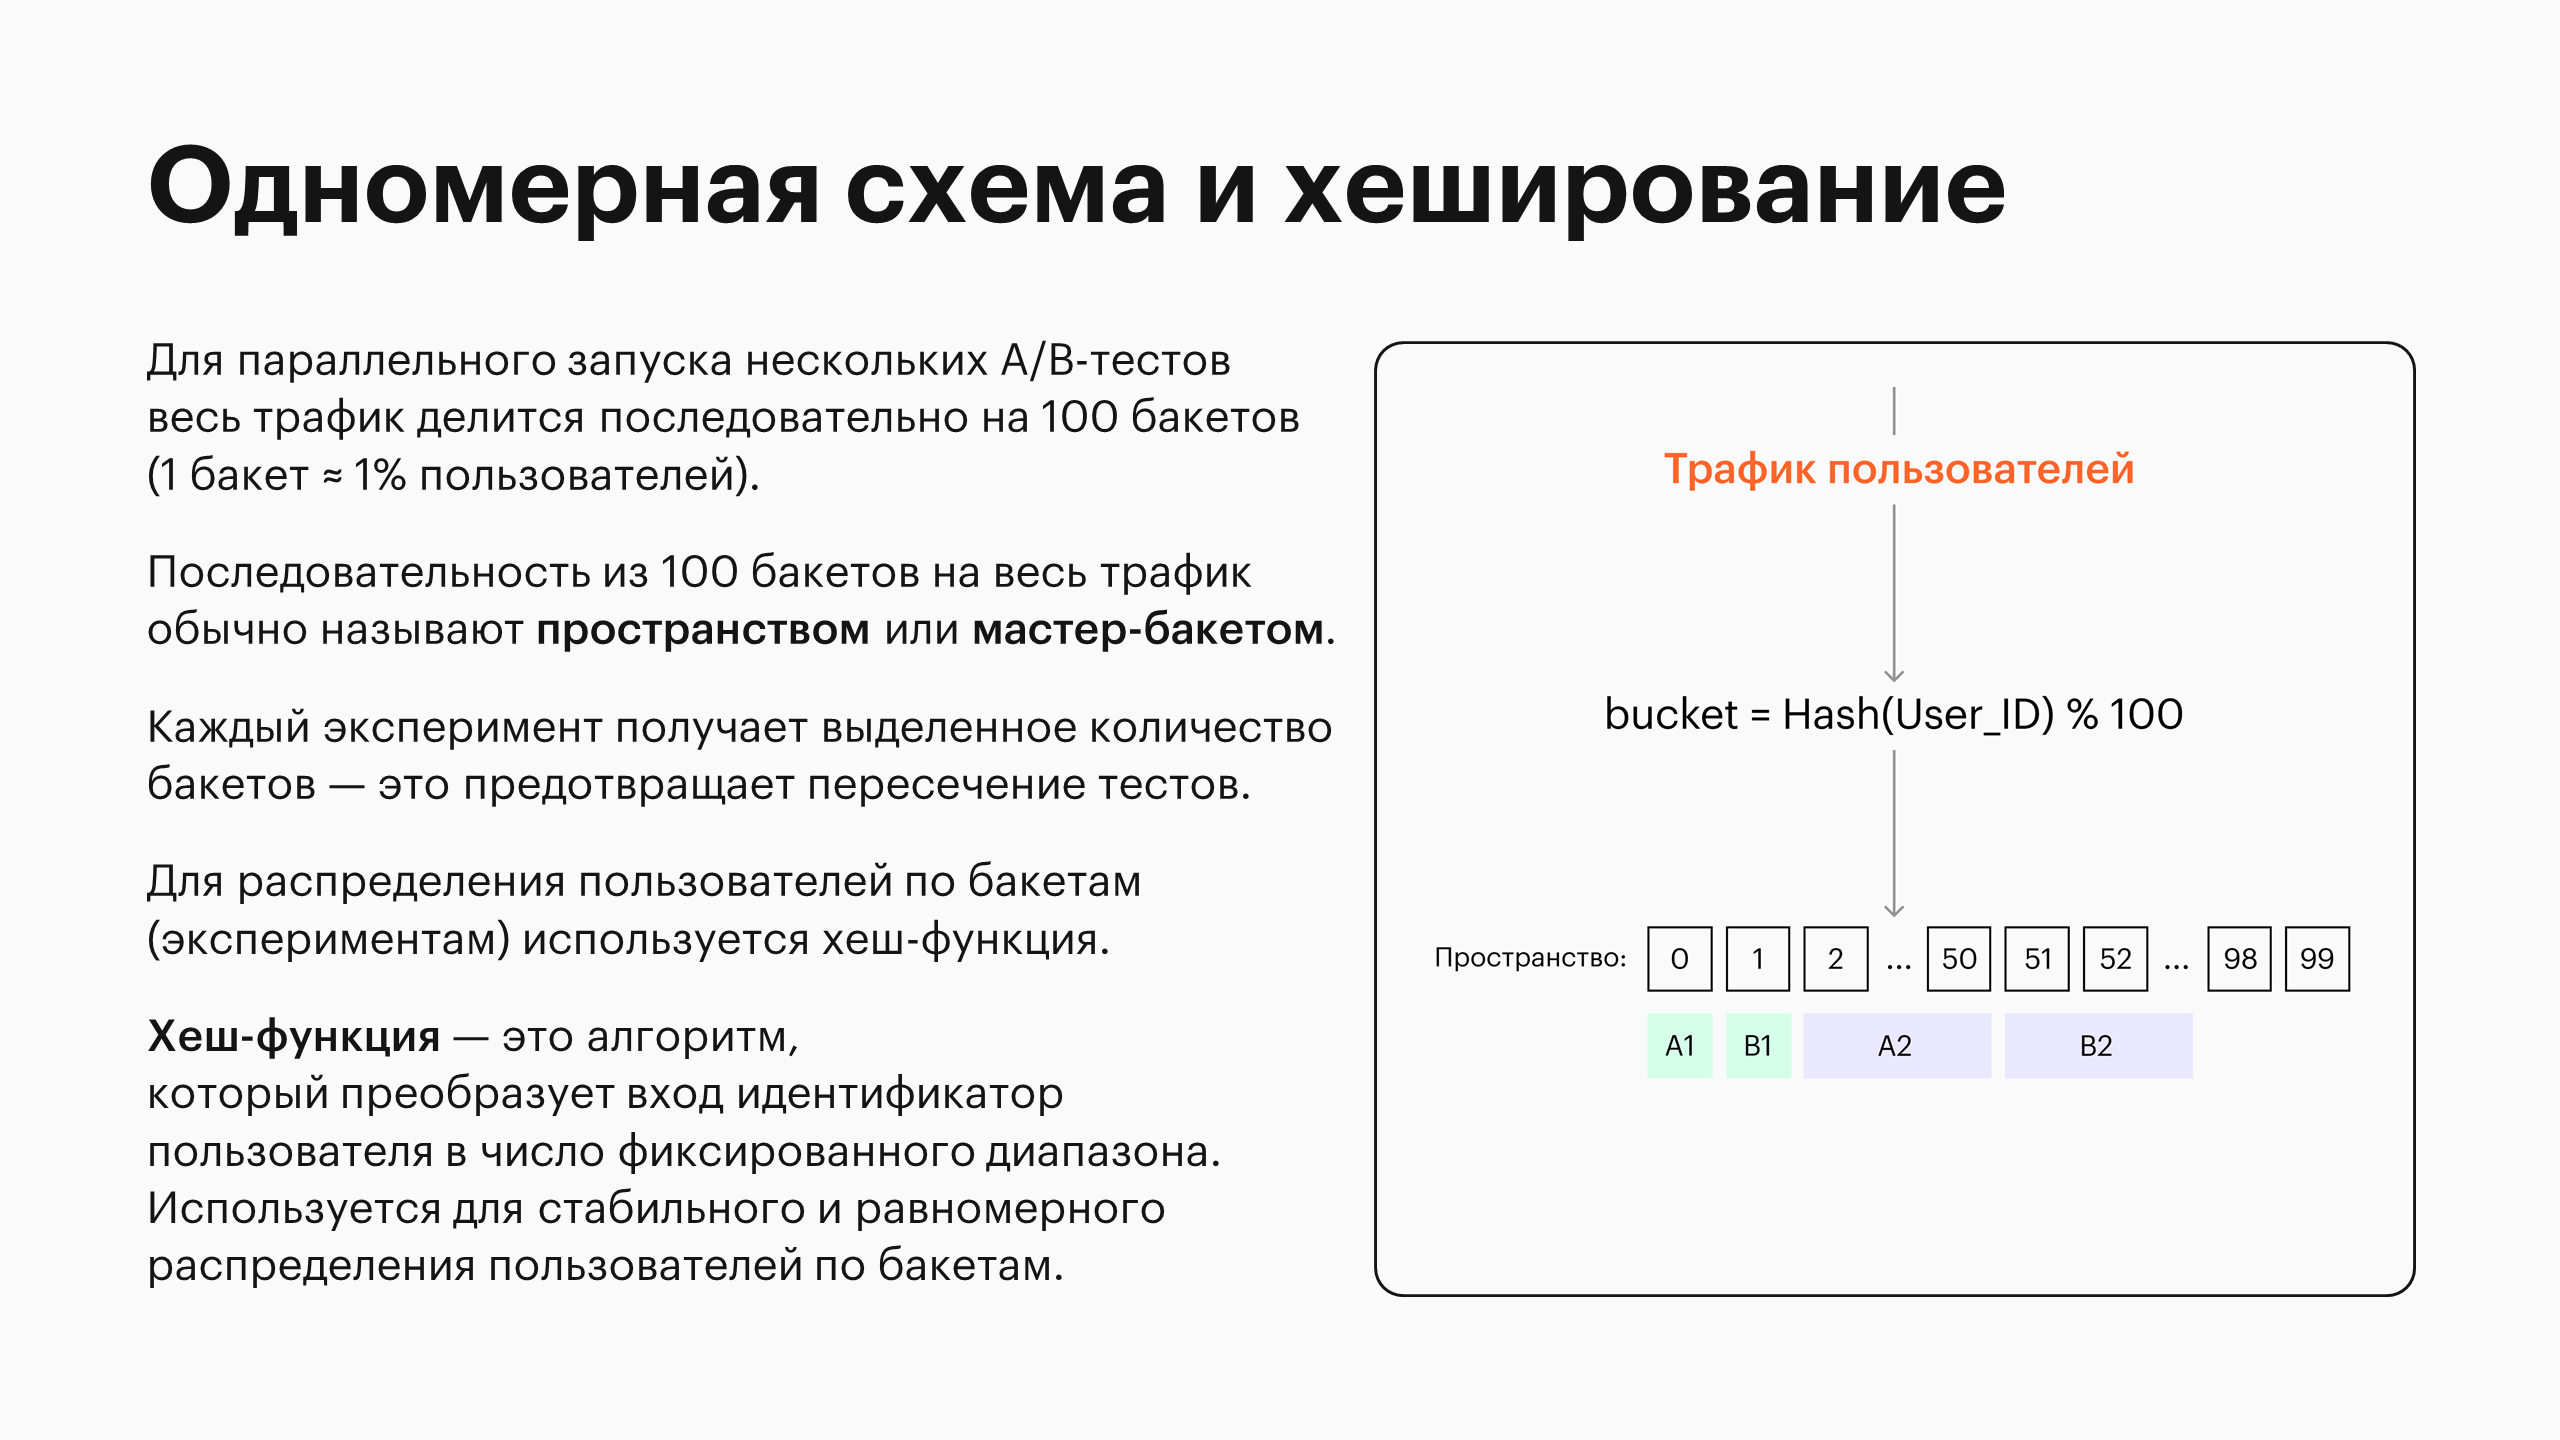

Разберём, как устроено **хеширование**.

**Хеширование** с помощью математического аппарата превращает любую входящую информацию в строку фиксированной длины с неочевидной связью между входной информацией и её *хешем*.

С помощью этой операции можно избавиться от проблемы, когда идентификаторы не случайны и определение группы по их значениям ведёт к дисбалансу групп.


Существует множество видов *хеширования*, и в рамках нашей задачи выбор между ними не играет роли, но самый распространённый — это MD5.

В качестве **примера** рассмотрим два идентификатора и применим к ним функцию хеширования.

In [ ]:
user_id_1 = 3125678545
user_id_2 = 31256785451

In [ ]:
import hashlib

# Преобразуем ID в строку, хешируем
# Переводим число из шестнадцатиричной системы в десятиричную
hash_user_id_1 = int(hashlib.md5(str(user_id_1).encode()).hexdigest(), 16)
hash_user_id_2 = int(hashlib.md5(str(user_id_2).encode()).hexdigest(), 16)

In [ ]:
print("Идентификатор 1 = ", user_id_1)
print("Длина идентификатора 1 = ", len(str(user_id_1)))
print()
print("Хеш-идентификатор 1 = ", hash_user_id_1)
print("Длина хеш-идентификатора 1 = ", len(str(hash_user_id_1)))

Идентификатор 1 =  3125678545
Длина идентификатора 1 =  10

Хеш-идентификатор 1 =  204795345348474395459258318245802261606
Длина хеш-идентификатора 1 =  39


In [ ]:
print("Идентификатор 2 = ", user_id_2)
print("Длина идентификатора 2 = ", len(str(user_id_2)))
print()
print("Хеш-идентификатор 2 = ", hash_user_id_2)
print("Длина хеш-идентификатора 2 = ", len(str(hash_user_id_2)))

Идентификатор 2 =  31256785451
Длина идентификатора 2 =  11

Хеш-идентификатор 2 =  247790041128078600012108724462180399102
Длина хеш-идентификатора 2 =  39


Посмотрим, в какие бакеты попали бы эти два пользователя.


In [ ]:
n_buck = 100

print(f'Пользователь 1 попадёт в бакет: {hash_user_id_1 % 100}')
print(f'Пользователь 2 попадёт в бакет: {hash_user_id_2 % 100}')

Пользователь 1 попадёт в бакет: 6
Пользователь 2 попадёт в бакет: 2


### Соль пространства и соль эксперимента

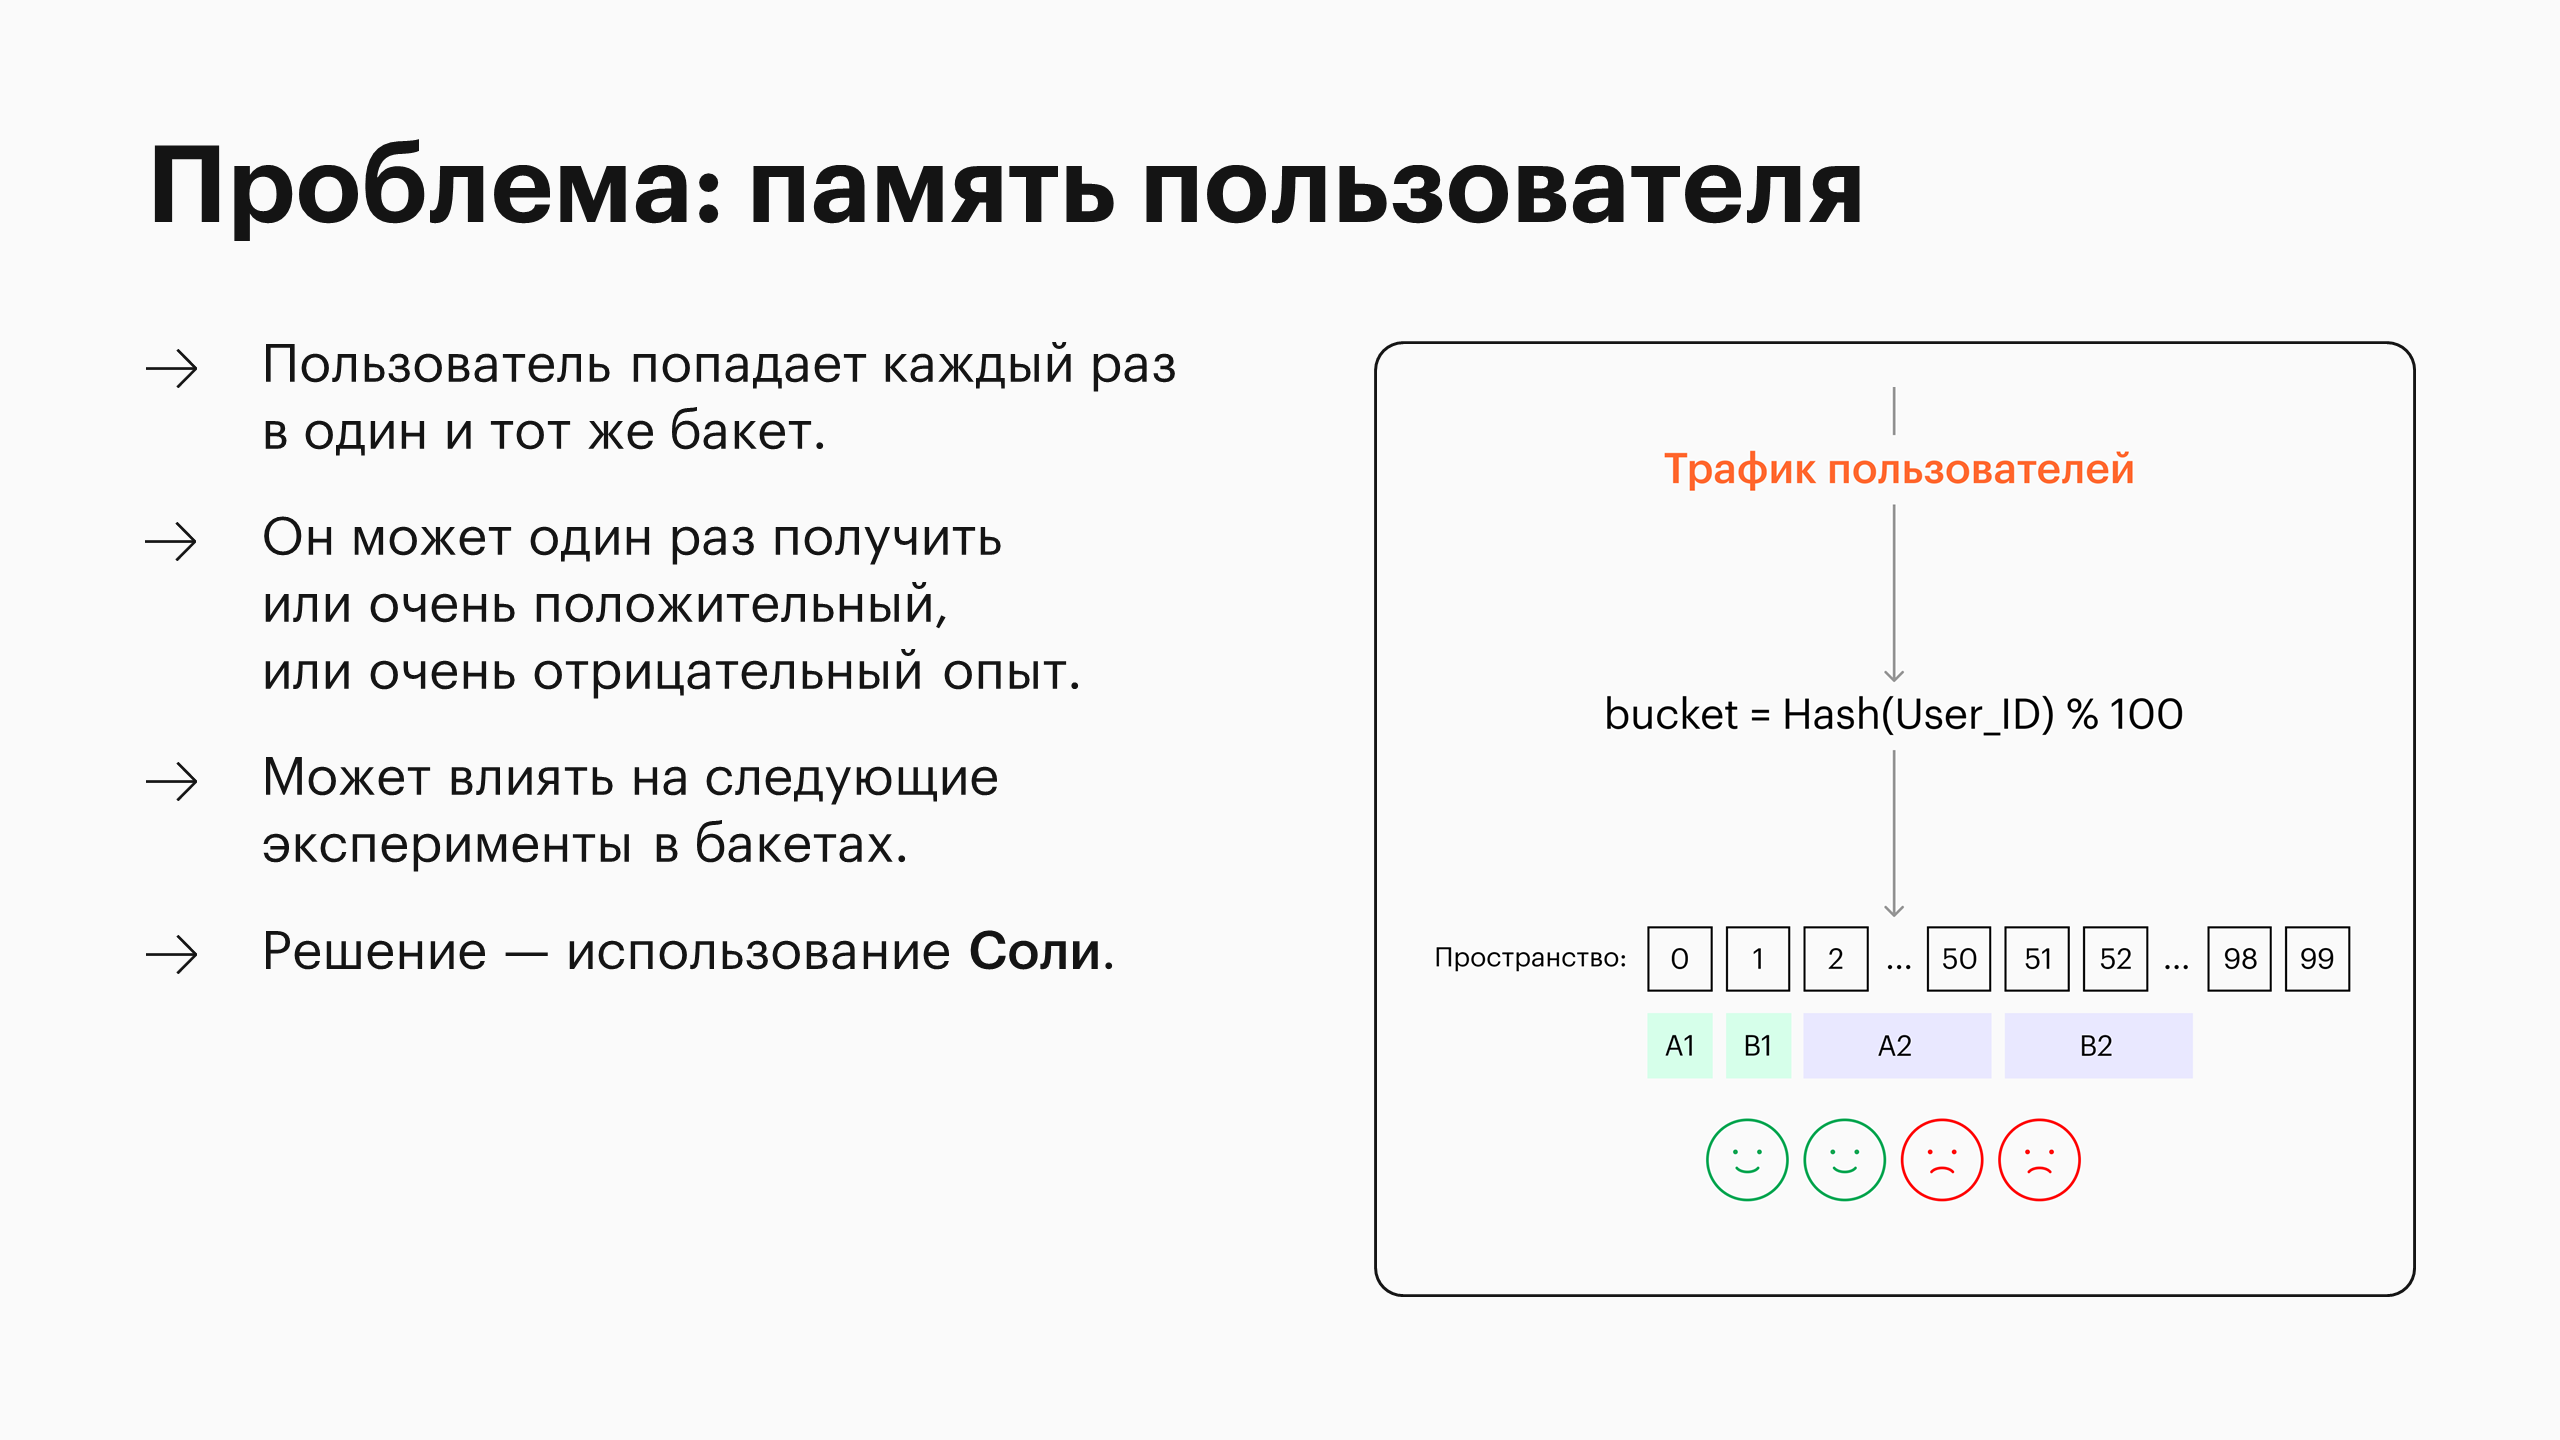

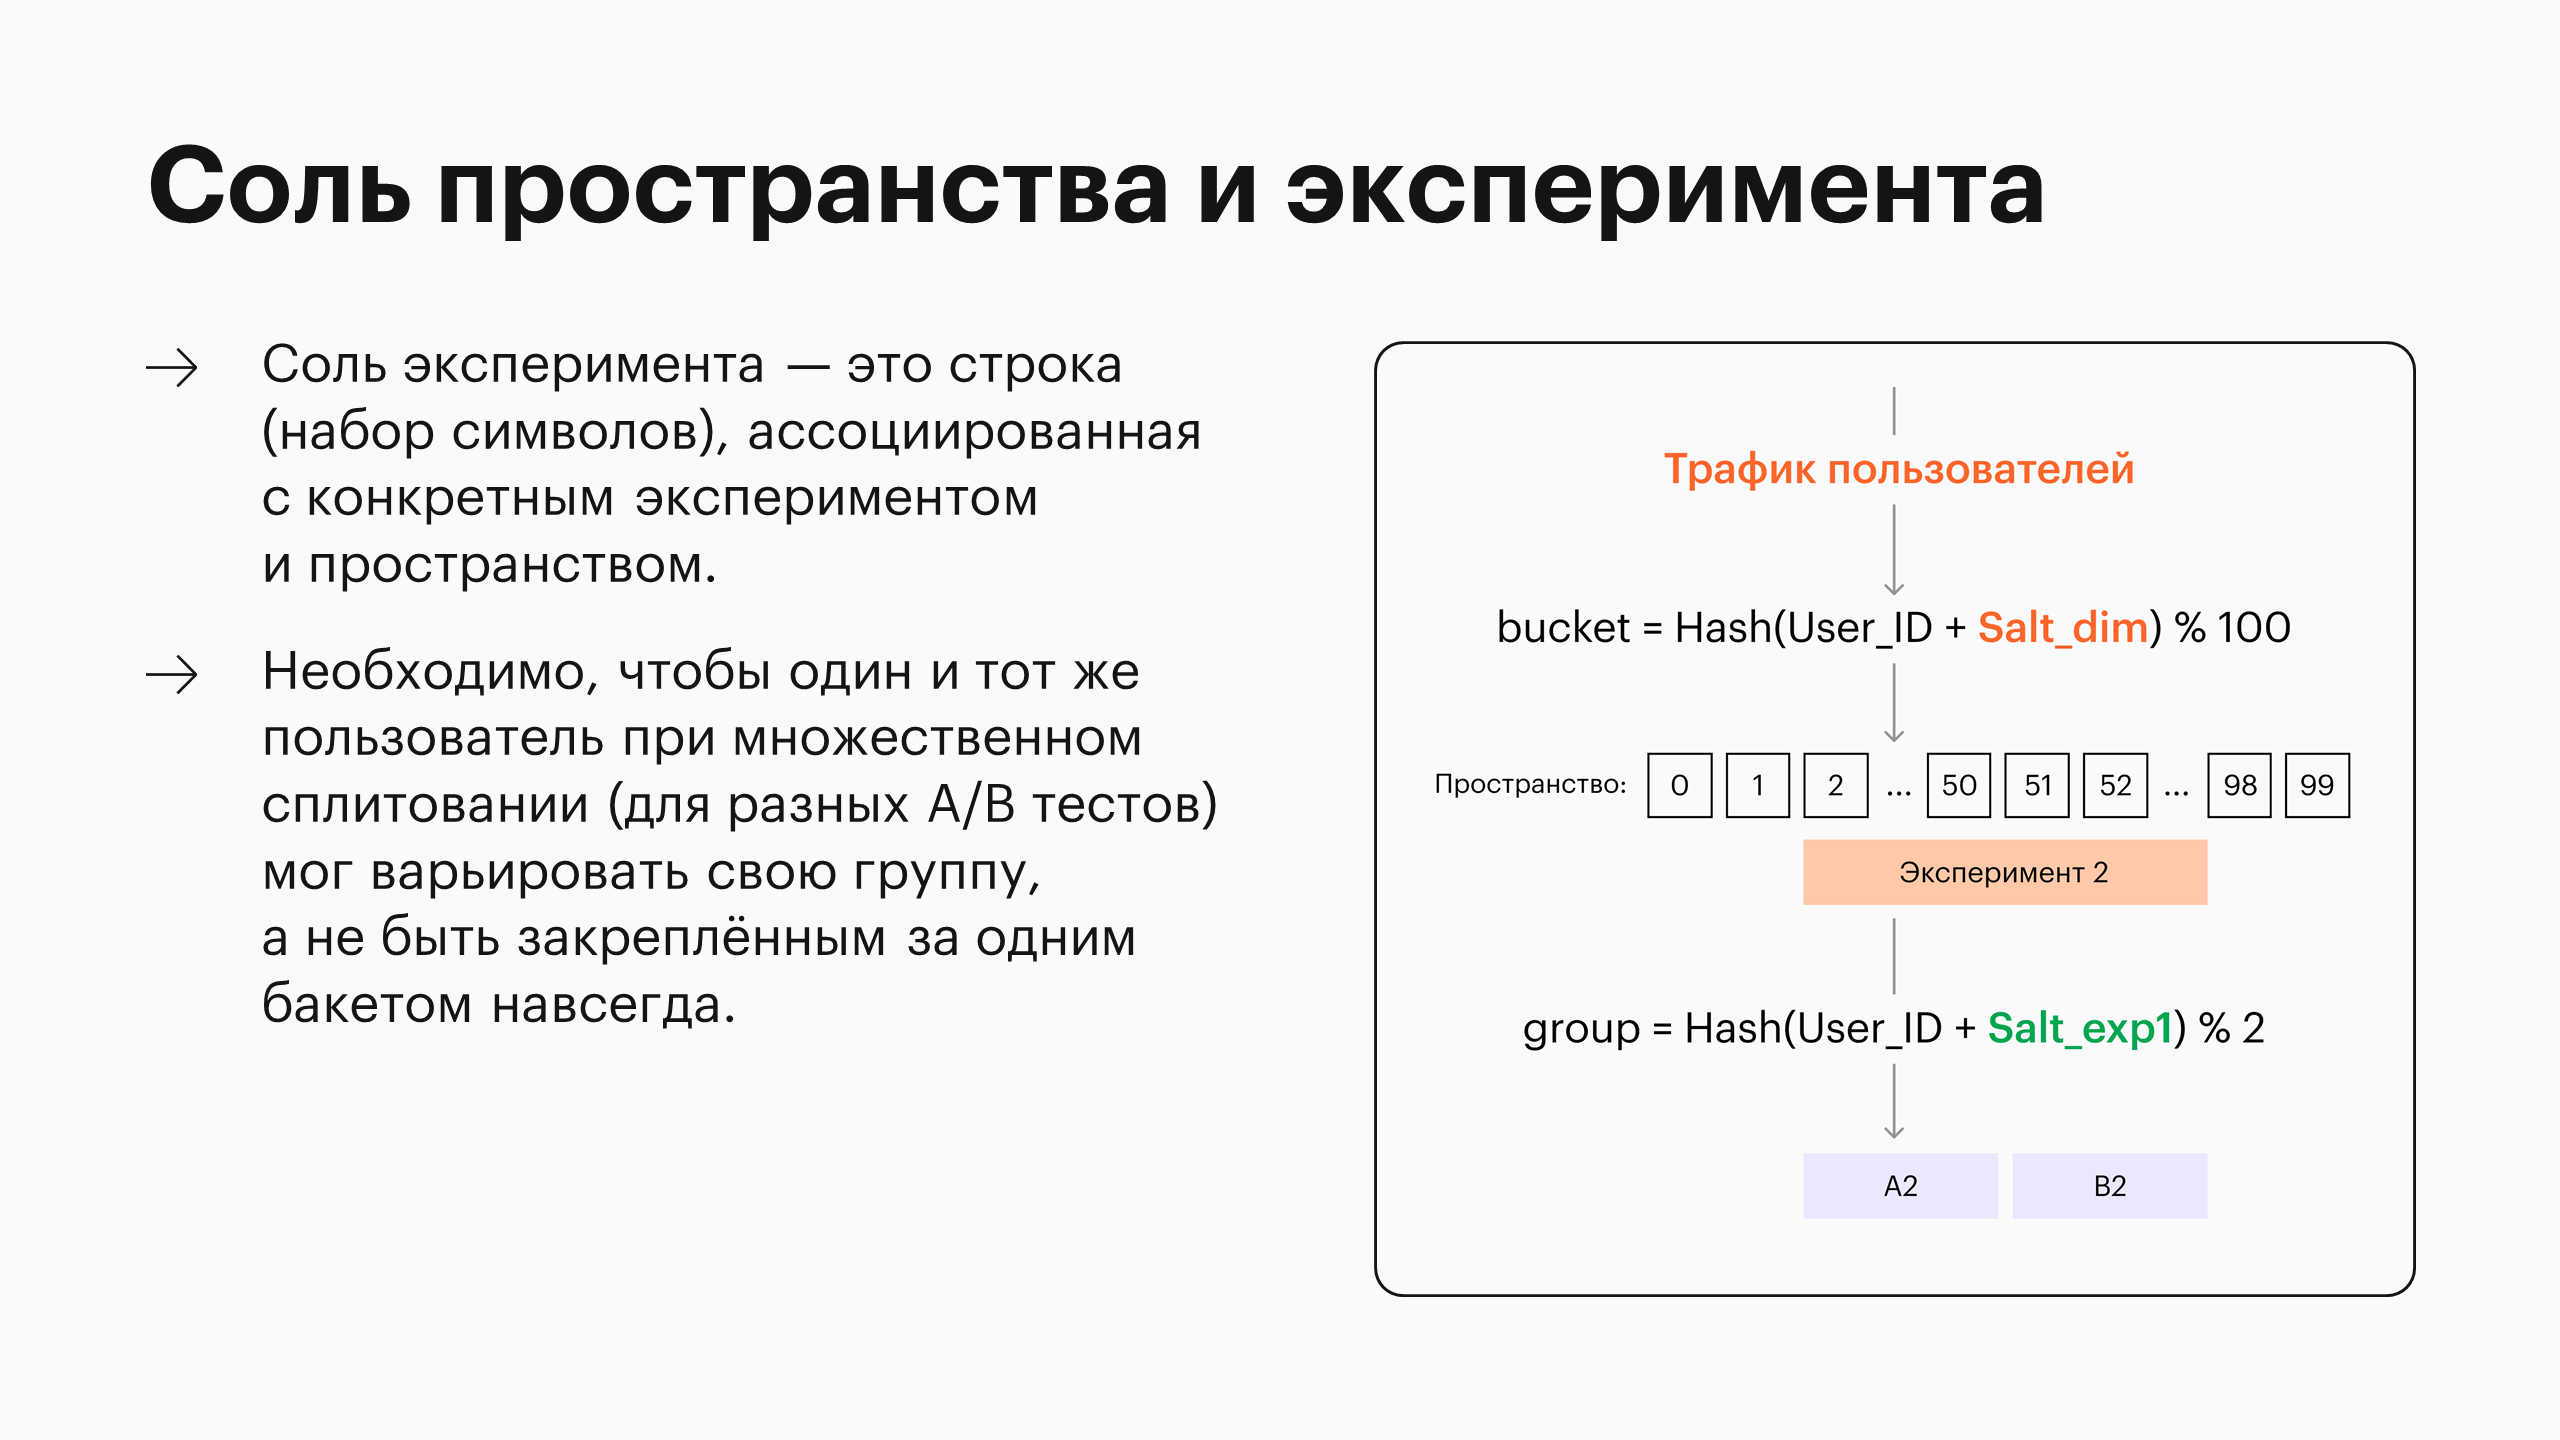

In [ ]:
user_id = '3abcF12R4E3SsPRc13A'

Найдём идентификатор с солью.

In [ ]:
dimension_salt = 'Dimension Salty Salt'
experiment_salt = 'Exp Sweety Salt'

In [ ]:
user_dim_salted_id = str(user_id) + dimension_salt
user_exp_salted_id = str(user_id) + experiment_salt

Хешируем идентификатор с солью.

In [ ]:
hash_user_dim_salted_id = int(hashlib.md5(user_dim_salted_id.encode()).hexdigest(), 16)
hash_user_exp_salted_id = int(hashlib.md5(user_exp_salted_id.encode()).hexdigest(), 16)

In [ ]:
print("Оригинальный айдишник = ", user_id)
print("Оригинальный айдишник + соль пространства = ", user_dim_salted_id)
print("Оригинальный айдишник + соль эксперимента = ", user_exp_salted_id)
print("Хеш (оригинальный айдишник + соль пространства) = ", hash_user_dim_salted_id)
print("Хеш (оригинальный айдишник + соль эксперимента) = ", hash_user_exp_salted_id)
print()
print(f'Пользователь попадёт в бакет – {hash_user_dim_salted_id % 100} и в группу – {hash_user_exp_salted_id % 2}')

Оригинальный айдишник =  3abcF12R4E3SsPRc13A
Оригинальный айдишник + соль пространства =  3abcF12R4E3SsPRc13ADimension Salty Salt
Оригинальный айдишник + соль эксперимента =  3abcF12R4E3SsPRc13AExp Sweety Salt
Хеш (оригинальный айдишник + соль пространства) =  74719715018091684172673231855517661153
Хеш (оригинальный айдишник + соль эксперимента) =  87400766171862374315061614923568288952

Пользователь попадёт в бакет – 53 и в группу – 0


Посмотрим, как меняется хешированный идентификатор при смене соли.

In [ ]:
salt1 = 'SALT1'
salt2 = 'SALT2'
salt3 = 'SALT3'

In [ ]:
print("Hash w Salt1 = ", int(hashlib.md5((str(user_id) + salt1).encode()).hexdigest(), 16))
print("Hash w Salt2 = ", int(hashlib.md5((str(user_id) + salt2).encode()).hexdigest(), 16))
print("Hash w Salt3 = ", int(hashlib.md5((str(user_id) + salt3).encode()).hexdigest(), 16))

Hash w Salt1 =  95949161666871644001710187872181275332
Hash w Salt2 =  147054059271977137748787897939710063903
Hash w Salt3 =  96796481465044245831336751035240545444


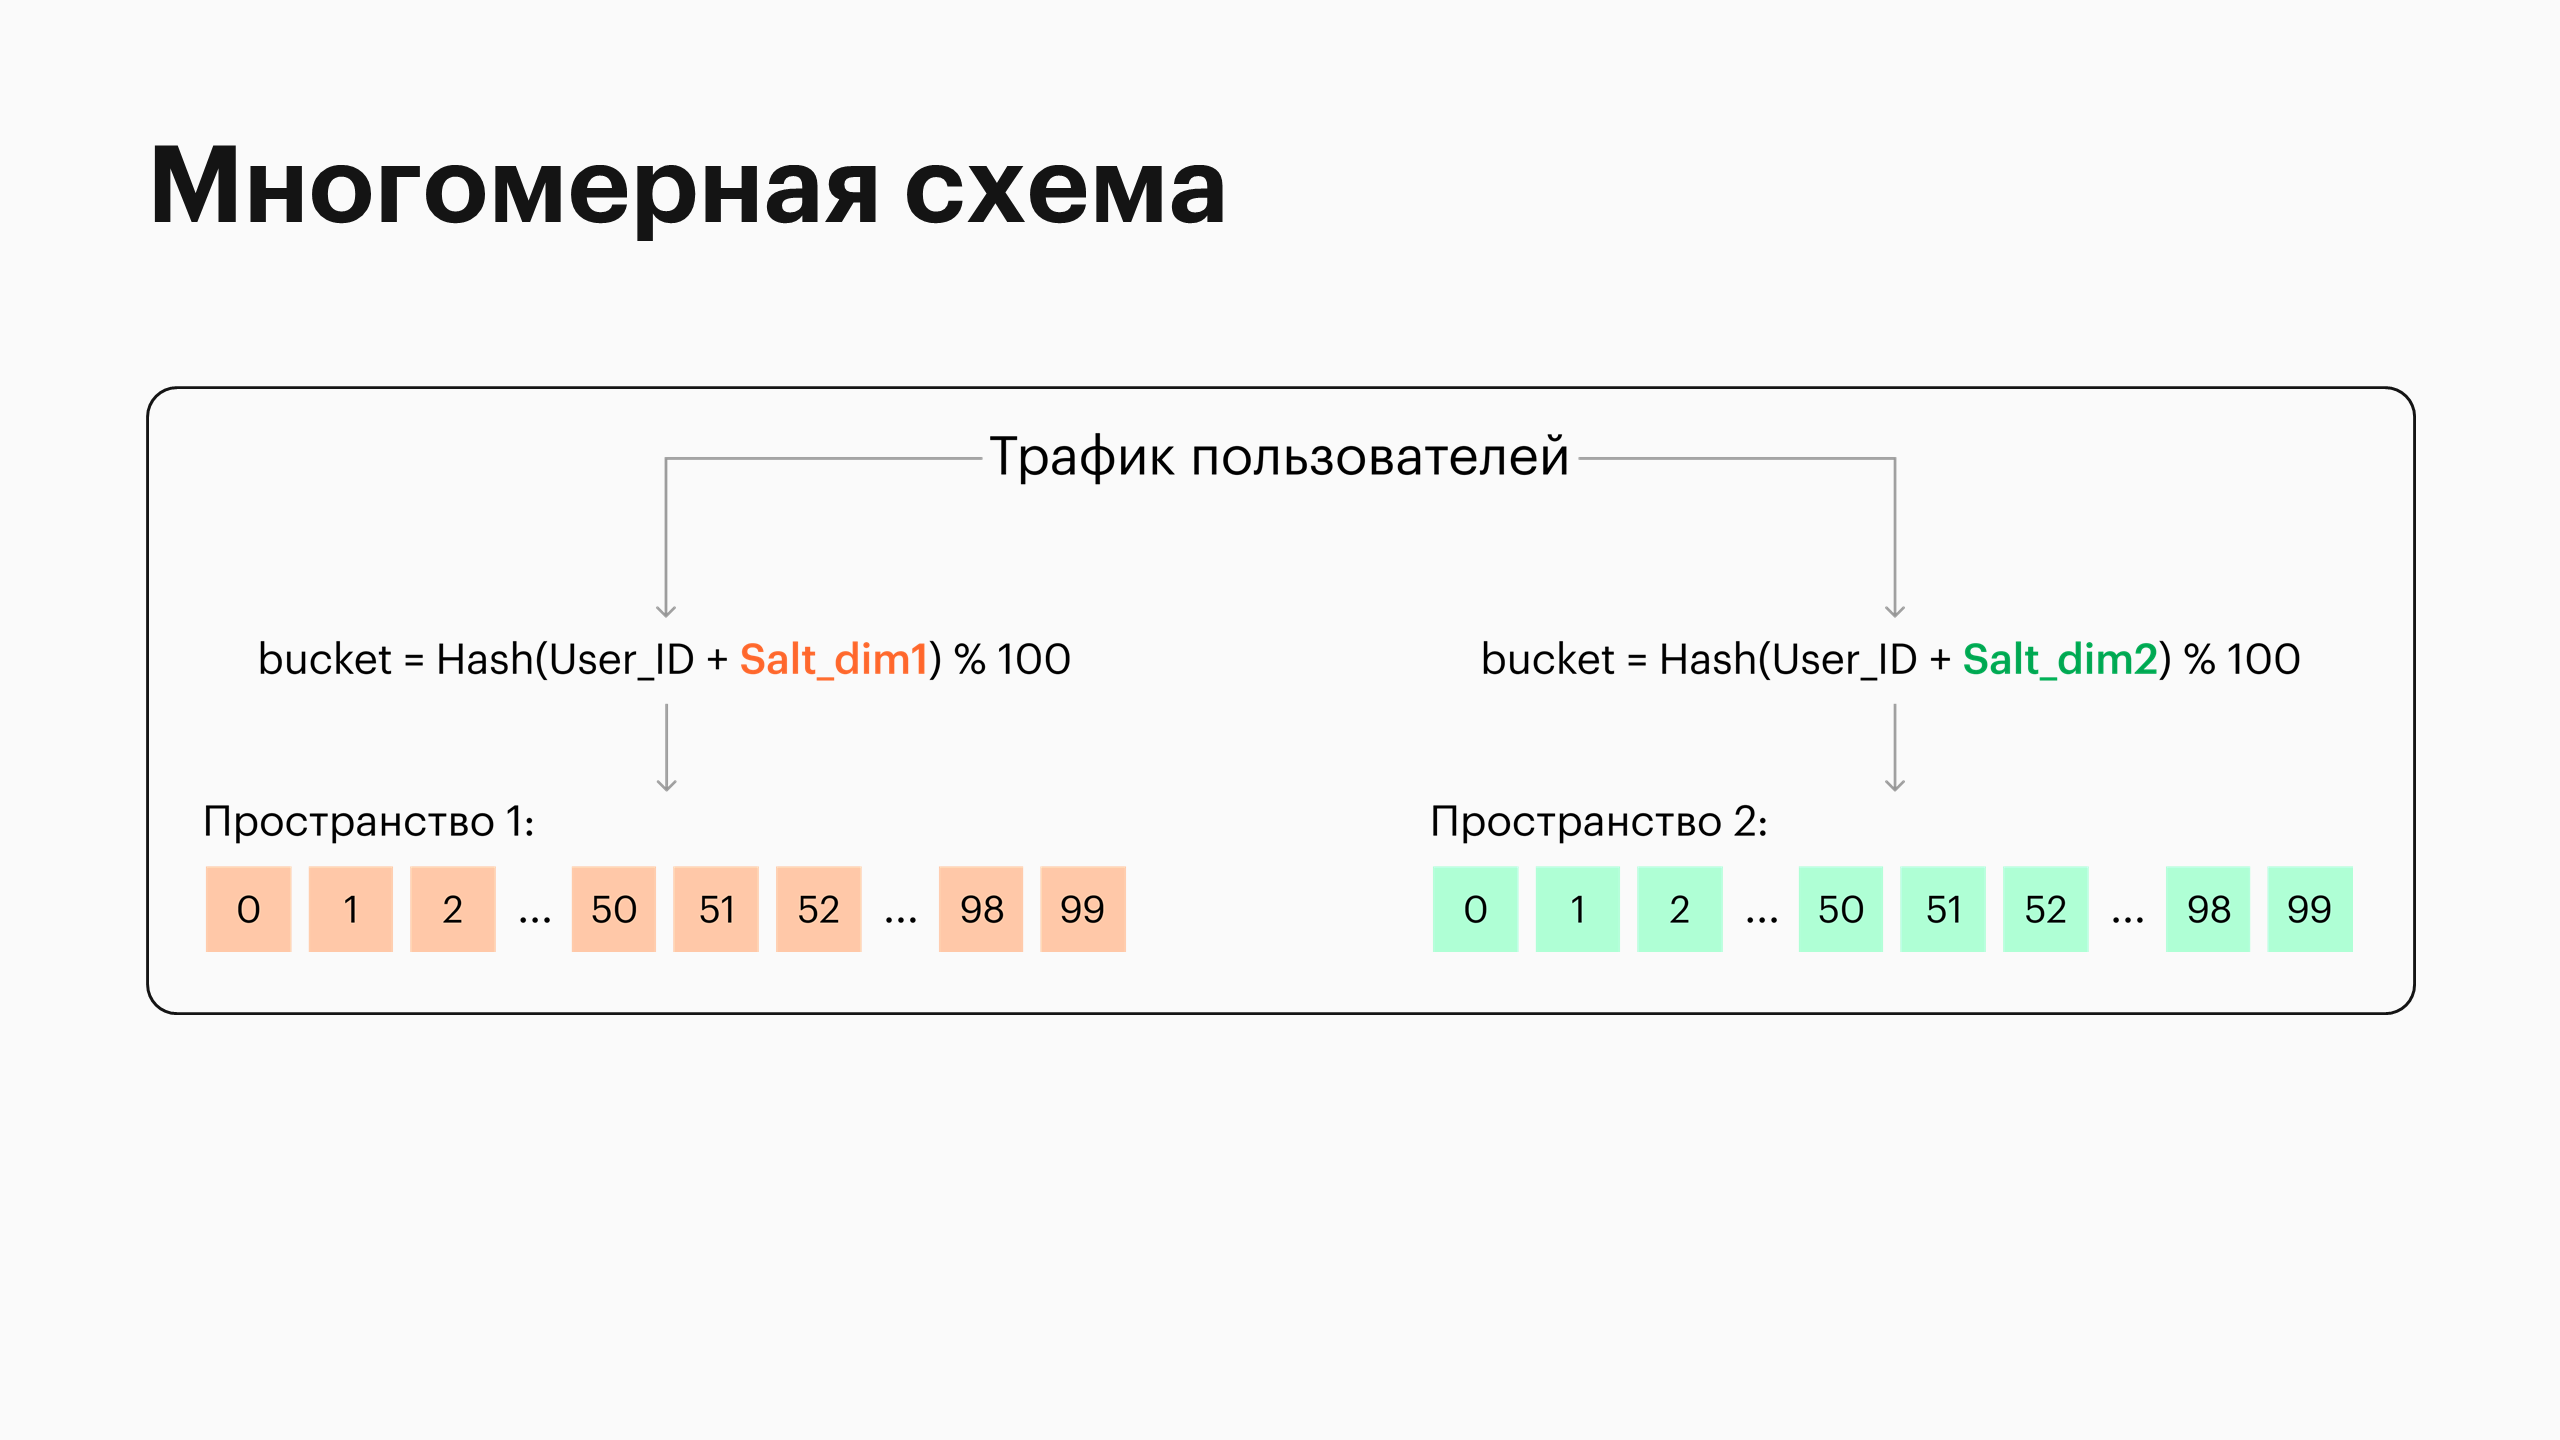

### АА-тест после хеширования и соли

Вернёмся к нашему датасету.

Создадим колонку датафрейма с хешированным идентификатором.

In [ ]:
def two_hash_fields(x, salt='salt_18'):
    s = f"{x}{salt}".encode()
    h = int(hashlib.md5(s).hexdigest(), 16)
    return h % 2, str(h)[-1]

In [ ]:
df_aa[['hash', 'hash_r_s']] = df_aa['id_client'].apply(two_hash_fields).apply(pd.Series)

In [ ]:
df_aa.head(5)

,id_client,amt_pay,is_user,group_last_id,r_s,hash,hash_r_s
0,2033218,2040,1,0,8,0,4
1,2072551,3246,1,1,1,1,5
2,2081474,2041,1,0,4,0,6
3,2023747,2475,1,1,7,0,6
4,2082766,715,1,0,6,0,2


Теперь разобьём пользователей уже по значению остатков от хеширования и проведём такую же процедуру АА-тестирования.

In [ ]:
df_c = df_aa[df_aa['hash']==0].copy()
df_t = df_aa[df_aa['hash']==1].copy()

In [ ]:
n_batch = 1000

# Перемешаем
df_c = df_c.sample(frac=1, random_state=18).reset_index(drop=True).copy()
df_t = df_t.sample(frac=1, random_state=28).reset_index(drop=True).copy()

# Режем на 1000 почти равных частей
idx_c_splits = np.array_split(np.arange(len(df_c)), n_batch)
idx_t_splits = np.array_split(np.arange(len(df_t)), n_batch)

parts_c = [df_c.iloc[idx] for idx in idx_c_splits]
parts_t = [df_t.iloc[idx] for idx in idx_t_splits]

In [ ]:
alpha=0.05

p_vals = []
# Сравним батчи попарно и посчитаем FPR
for i in range(n_batch):
    a = parts_c[i]
    b = parts_t[i]

    num_t, denom_t = get_signals(a, 'amt_pay', 'is_user')
    num_c, denom_c = get_signals(b, 'amt_pay', 'is_user')
    _, _, _, _, _, pval = get_stats_res(num_t, denom_t, num_c, denom_c)
    p_vals.append(pval)


p_vals = np.array(p_vals)
fpr = sum(p_vals < alpha) / n_batch

'False Positive Rate: 4.2 %'

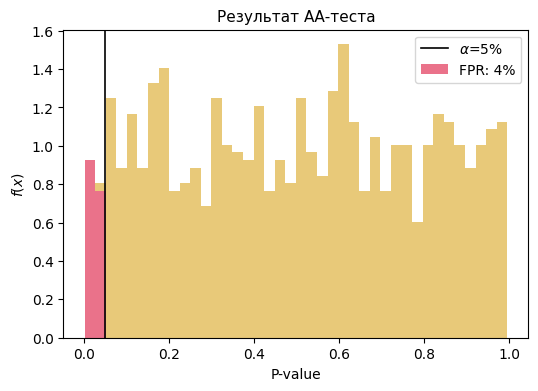

In [ ]:
cond = p_vals < 0.05
plt.axvline(0.05, color='black', linewidth=1.2, label=r'$\alpha$=5%')
plt.hist([p_vals[cond], p_vals[~cond]], bins=40, color=['crimson', 'goldenrod'], density=True,
        histtype='barstacked', label=[f'FPR: {round(100*fpr)}%', ''], alpha=0.6)
plt.title('Результат АА-теста', fontsize=11)
plt.xlabel('P-value', fontsize=10)
plt.ylabel('$f(x)$', fontsize=10)
plt.legend(loc=1, fontsize=10)


f'False Positive Rate: {round(100.0 * fpr, 2)} %'

Теперь вновь попробуем найти зависимость между последним символом идентификатора и размером платежа.

In [ ]:
i_l_df = []
m_l_df = []
n_l_df = []

for i in df_aa['hash_r_s'].unique():
  i_l_df.append(i)

  n = len(df_aa[df_aa['hash_r_s']==i]['amt_pay'])
  n_l_df.append(n)

  m = df_aa[df_aa['hash_r_s']==i]['amt_pay'].mean()
  m_l_df.append(m)

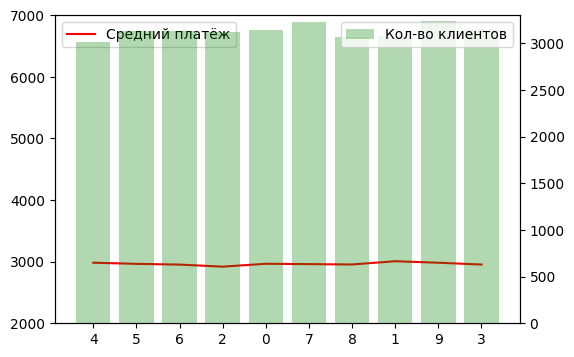

In [ ]:
plt.rcParams["figure.figsize"] = (6,4)

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.plot(i_l_df, m_l_df, color = 'red', label = 'Средний платёж')
ax2.bar(i_l_df, n_l_df, color = 'green', alpha = .3, label = 'Кол-во клиентов')
ax1.legend(loc = 'upper left')
ax2.legend(loc = 'upper right')
ax1.set_ylim([2000, 7000])
ax2.set_ylim([0, 3300])
plt.show()

**Вывод**

Мы избавились от нежелательных закономерностей в идентификаторах с помощью хеширования и теперь можем применить простую логику разделения на группы (например, чётность последнего символа хеш-значения).

# Поправка на множественное тестирование

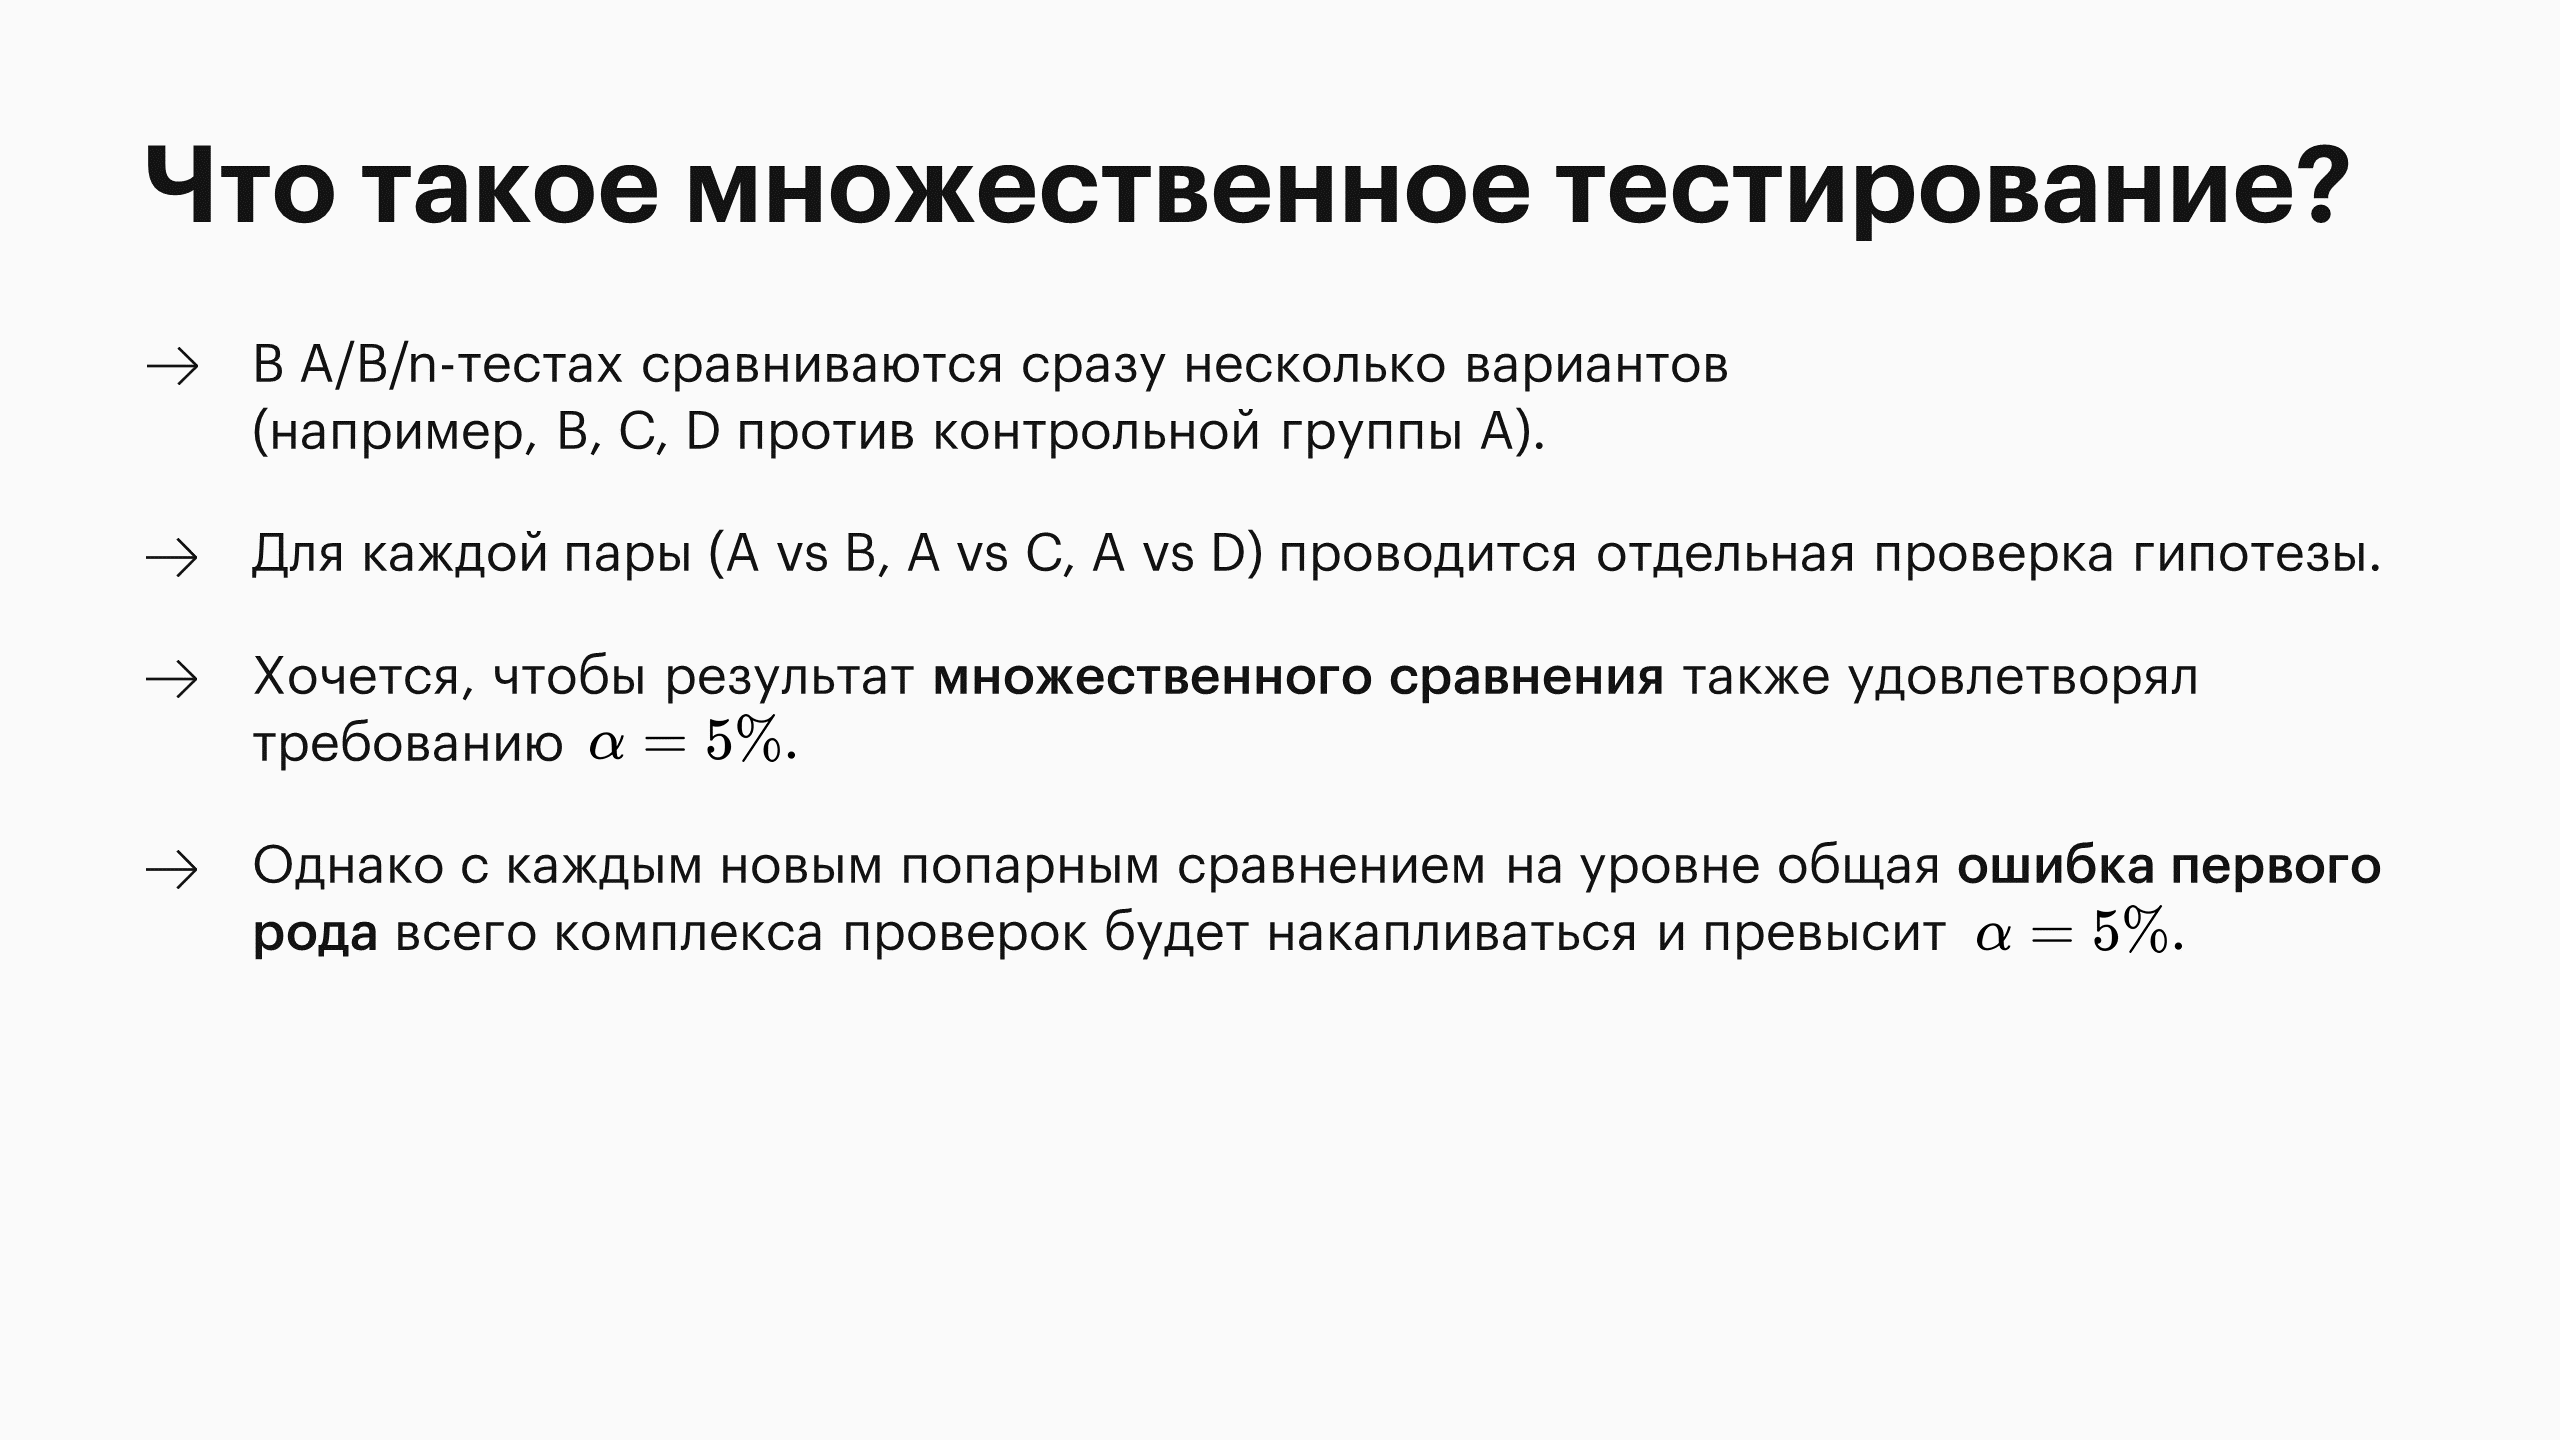

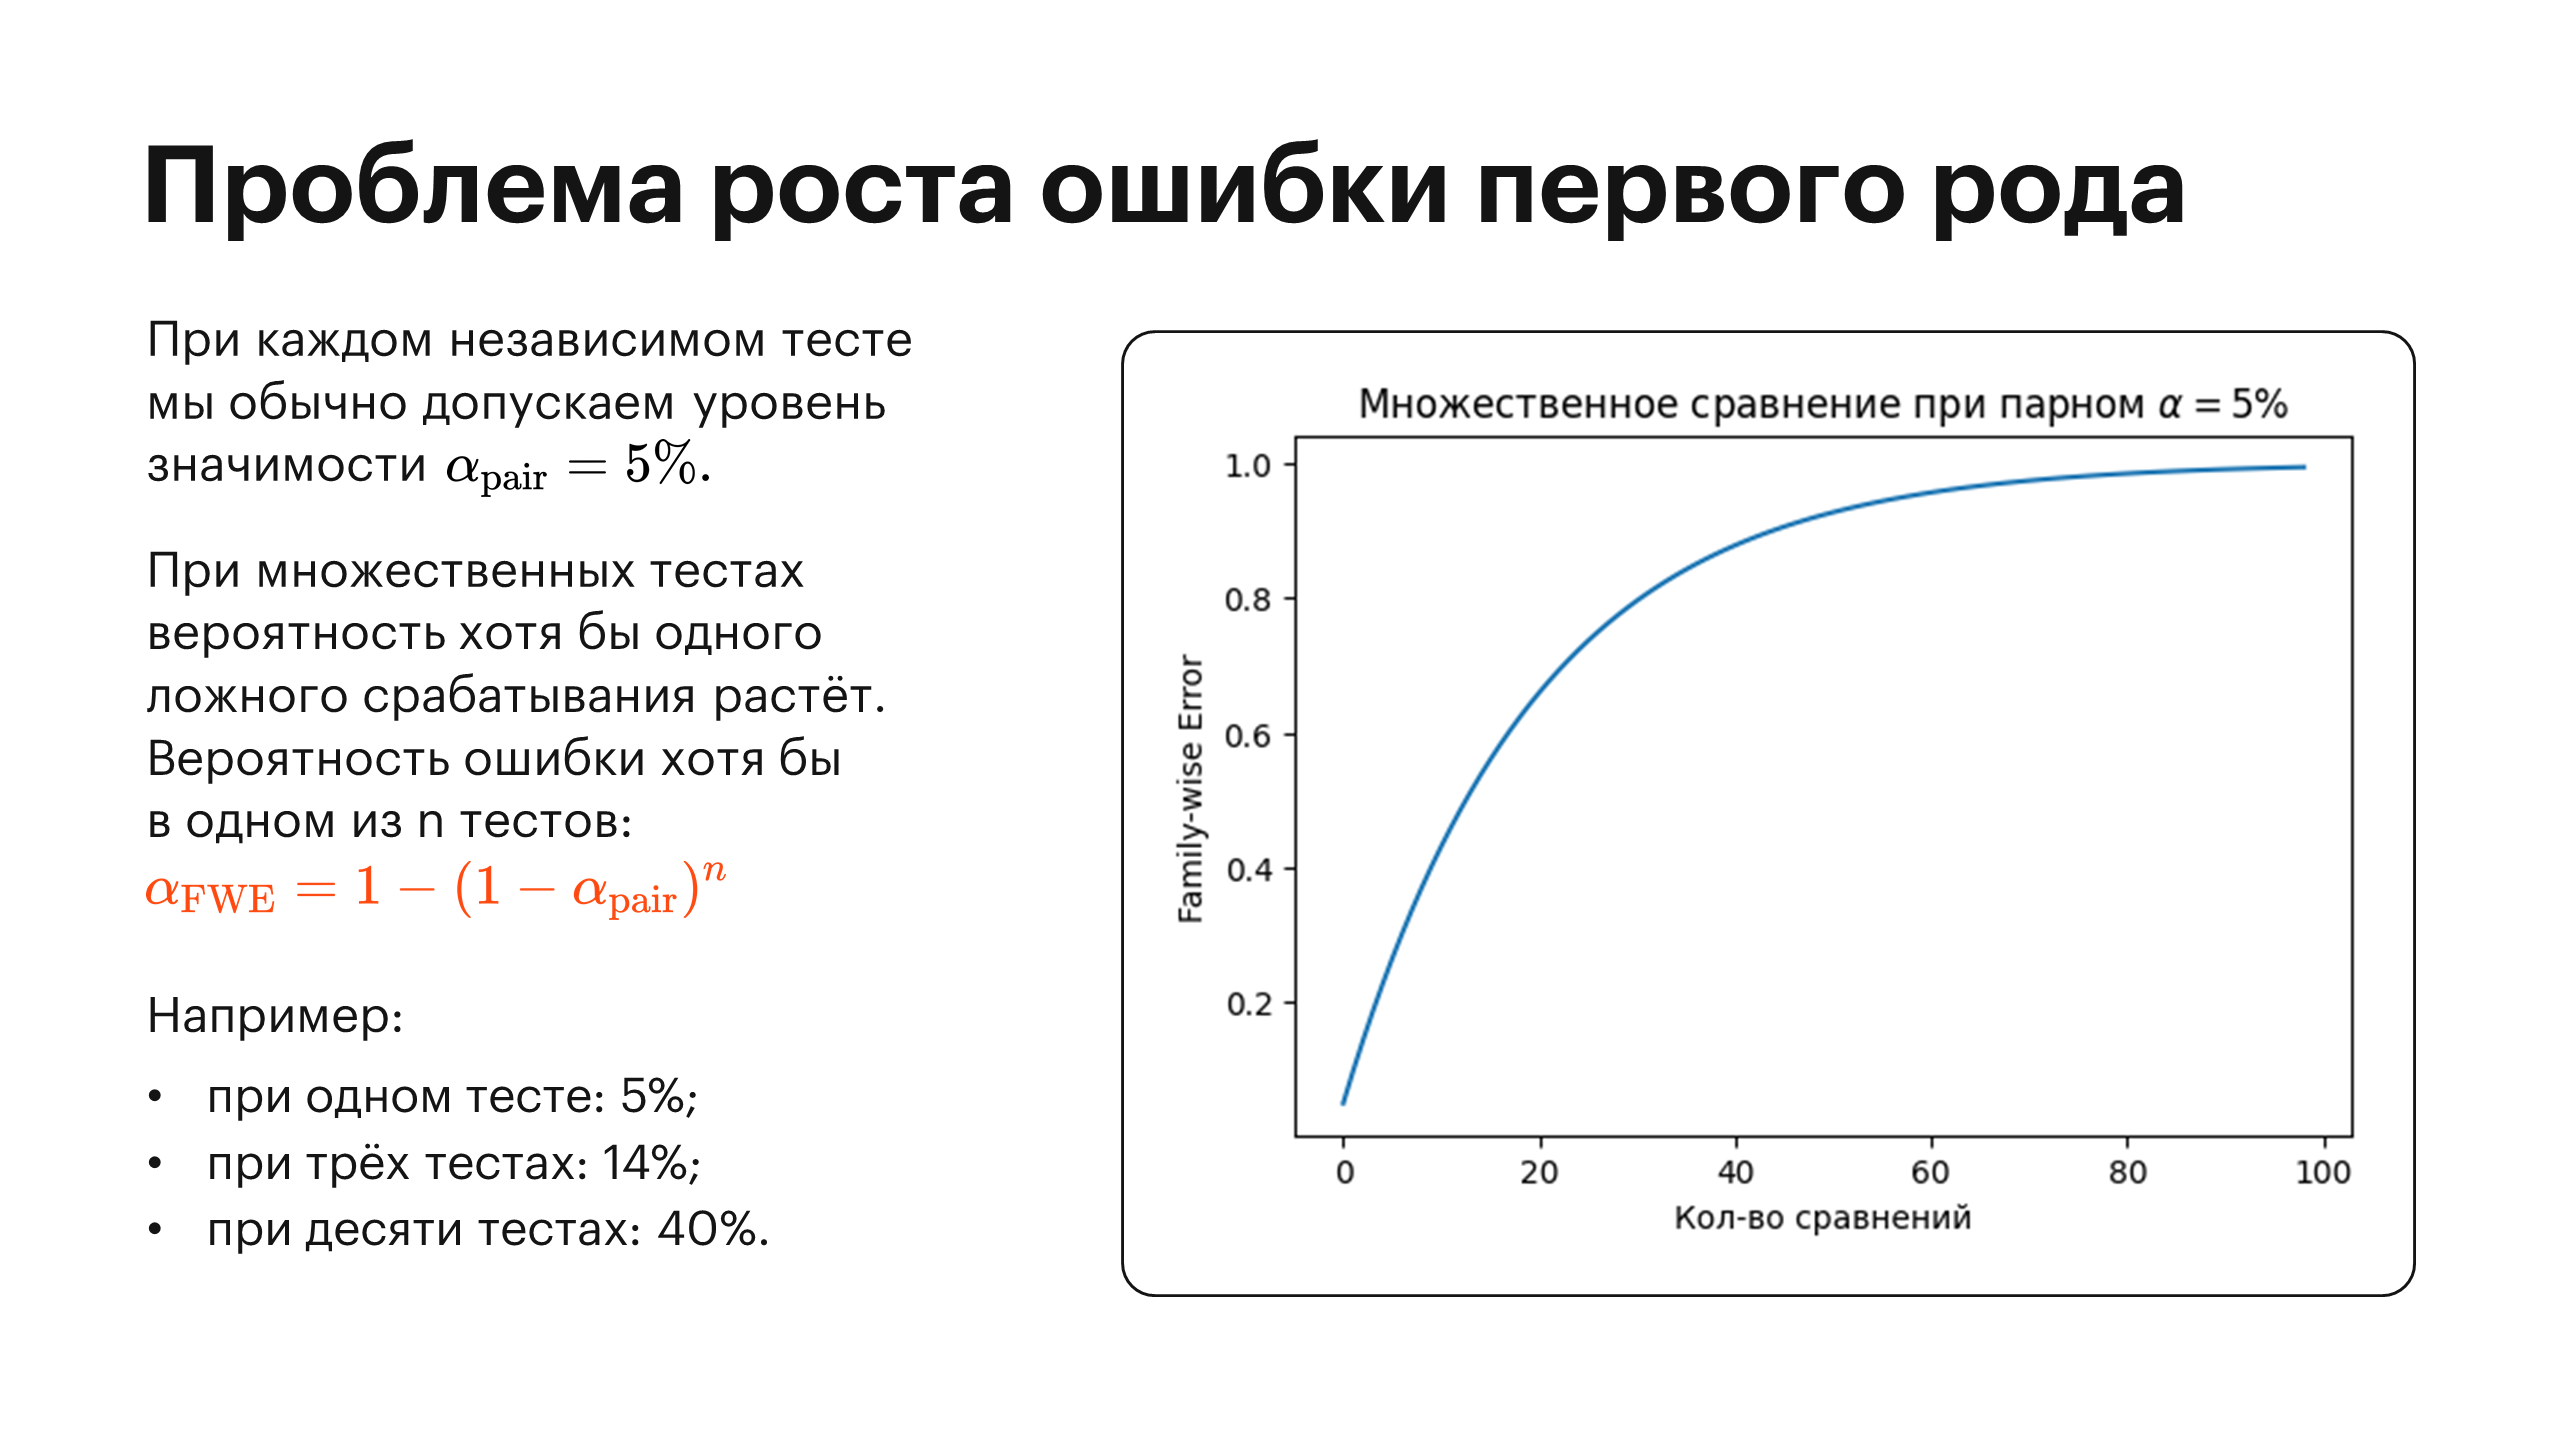

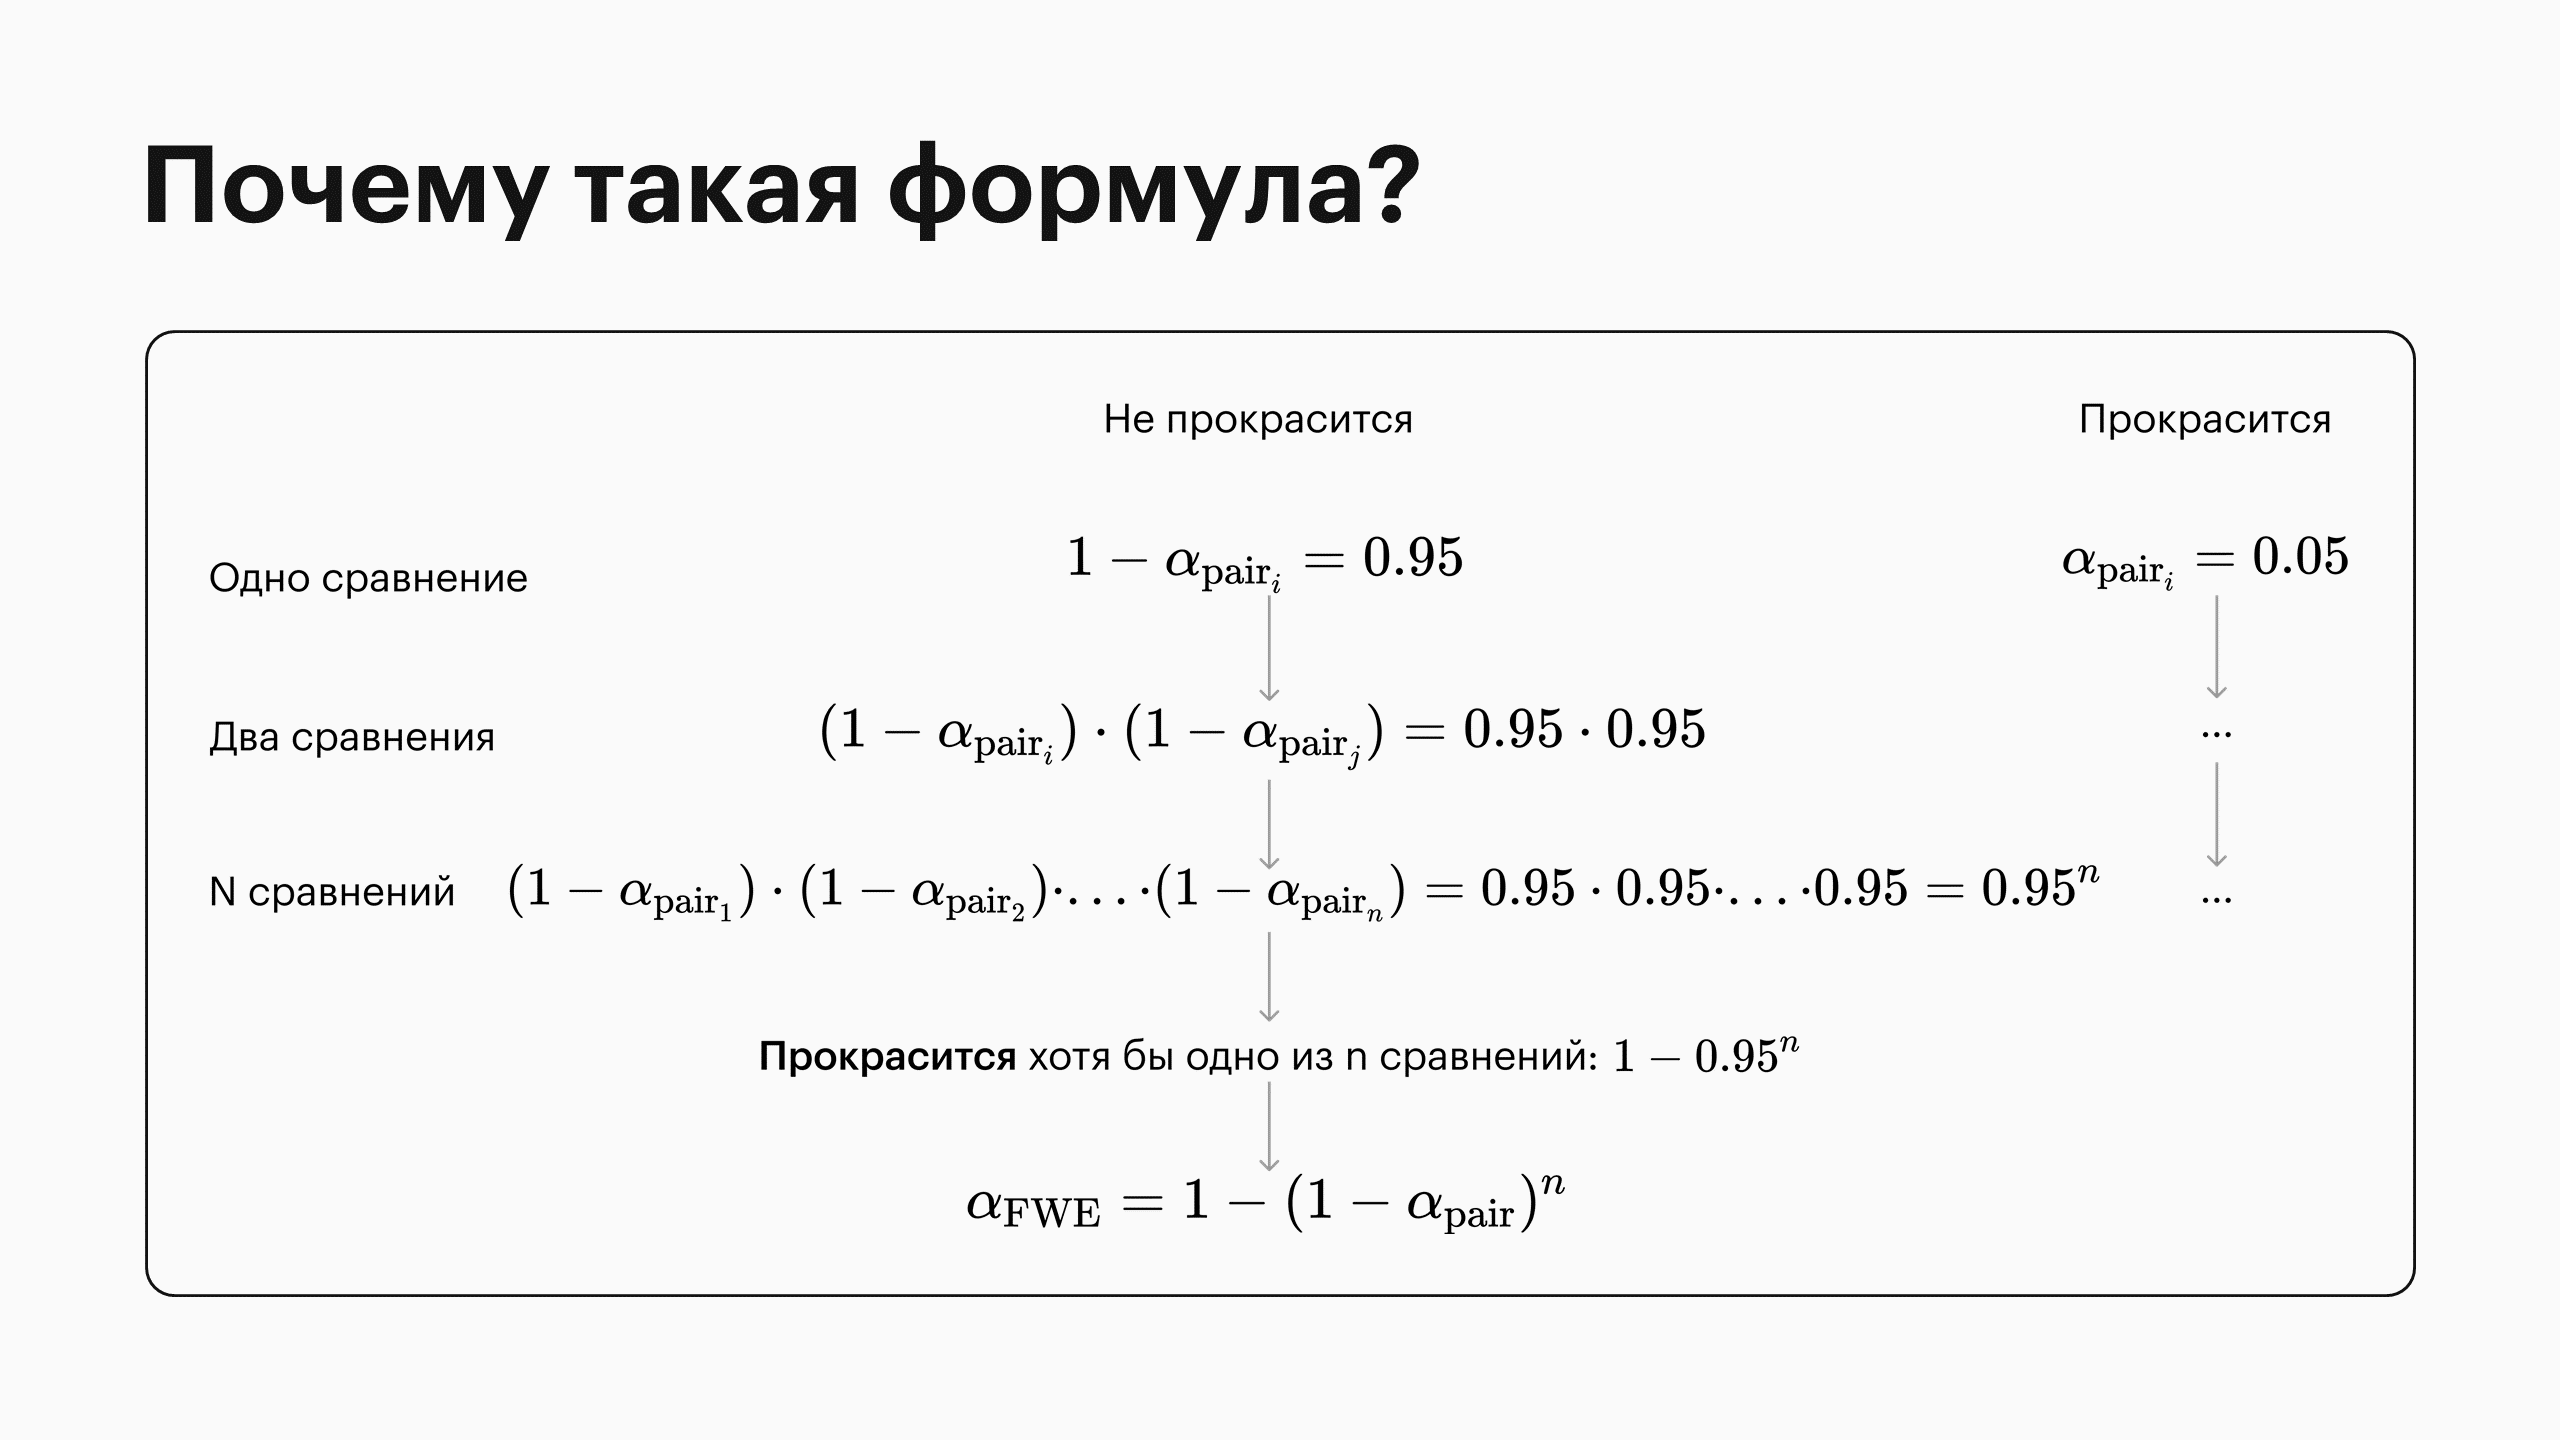

Формула, по сути, отвечает на вопрос, какая вероятность того, что прокрасится рандомно хотя бы одно сравнение на уровне $\alpha_{\operatorname{pair}}.$

Очевидно, что в случае обычного A/B теста (то есть для $n=1$) имеем:
$$\alpha_{\operatorname{pair}}=\alpha_{\operatorname{FWE}}.$$

Посмотрим на изменение $\alpha_{\operatorname{FWE}}$ в зависимости от $n$ для $\alpha_{\operatorname{pair}}=5\%$.

Например, для $n=2$:

$$1 - (1-0,05)^2 = \alpha_{\operatorname{FWE}}.$$



In [ ]:
alpha_pair = .05
fwes = []

for i in range(1,100):
  fwes.append(1 - (1-alpha_pair)**i)

fwes[:5]

[0.050000000000000044,
 0.09750000000000003,
 0.1426250000000001,
 0.18549375000000012,
 0.22621906250000023]

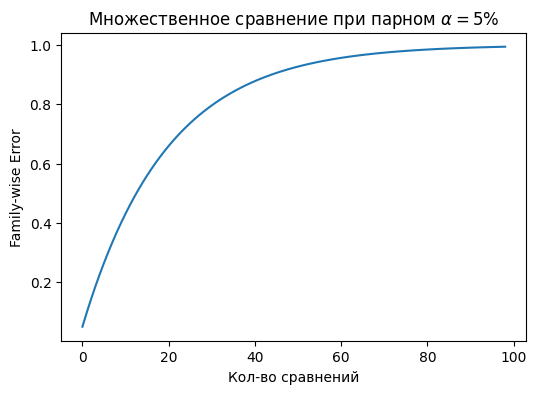

In [ ]:
plt.plot(fwes)
plt.title(r"Множественное сравнение при парном $\alpha=5\%$")
plt.xlabel("Кол-во сравнений")
plt.ylabel("Family-wise Error")
plt.show()

## Поправка Бонферони

Можно теперь выразить $\alpha_{\operatorname{pair}}$ через $\alpha_{\operatorname{FWE}}$.

Получим для $n=2$:

$$\alpha_{\operatorname{pair}} = 1 - \sqrt{1-\alpha_{\operatorname{FWE}}}.$$

А для произвольного $n$:

$$\alpha_{\operatorname{pair}} = 1 - \sqrt[n]{1-\alpha_{\operatorname{FWE}}}.$$

In [ ]:
pairs_math = []

for i in fwes:
  pairs_math.append(1 - (1 - i)**(1 / (fwes.index(i) + 1)))

pairs_math[:7]

[0.050000000000000044,
 0.050000000000000044,
 0.050000000000000044,
 0.050000000000000044,
 0.050000000000000044,
 0.050000000000000044,
 0.050000000000000044]

Стоит отметить, что функция $f(n) = \sqrt[n]{1-\alpha}$ апроксимируется функцией $f(n) = \frac{\alpha}{n}.$

Давайте просто проверим на их значениях.

In [ ]:
def func_1(n):
  return 1 - (1 - 0.05)**(1 / n)

def func_2(n):
  return 0.05 / n

x = range(1,100)
y1 = list(map(func_1, x))
y2 = list(map(func_2, x))

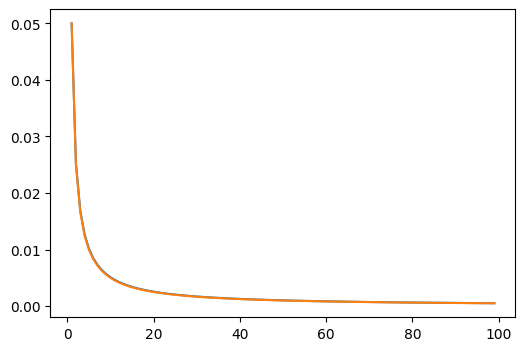

In [ ]:
plt.plot(x, y1)
plt.plot(x, y2)
plt.show()

In [ ]:
pairs = []

for i in fwes:
  pairs.append(i / (fwes.index(i) + 1))

pairs[:5]

[0.050000000000000044,
 0.048750000000000016,
 0.047541666666666704,
 0.04637343750000003,
 0.04524381250000005]

Таким образом, переходим к упрощённой формуле:

$$\alpha_{pair} = \frac{\alpha_{FWE}}{n},$$

то есть, если вы хотите с $95\%$-ной вероятностью не совершить ошибку первого рода при вынесении решения, основанного на нескольких попарных тестах, вам необходимо проводить попарные проверки на меньшем уровне значимости, то есть с большей вероятностью не разглядеть «прокрас».

## Поправка Холма

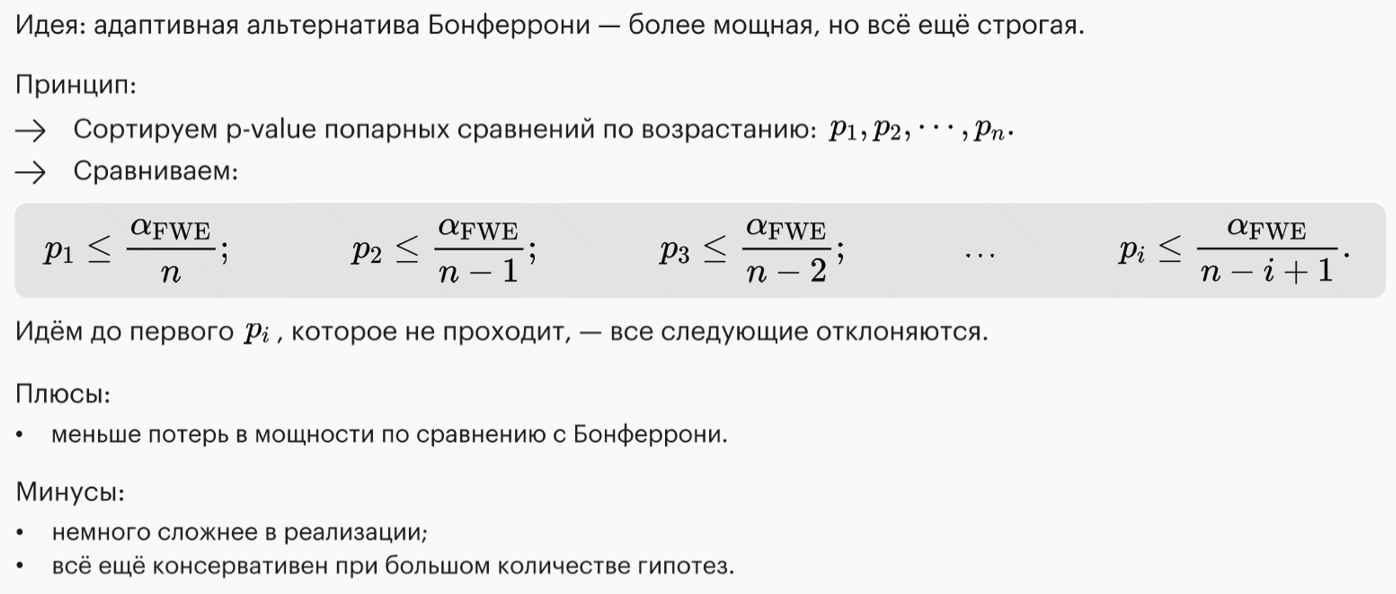

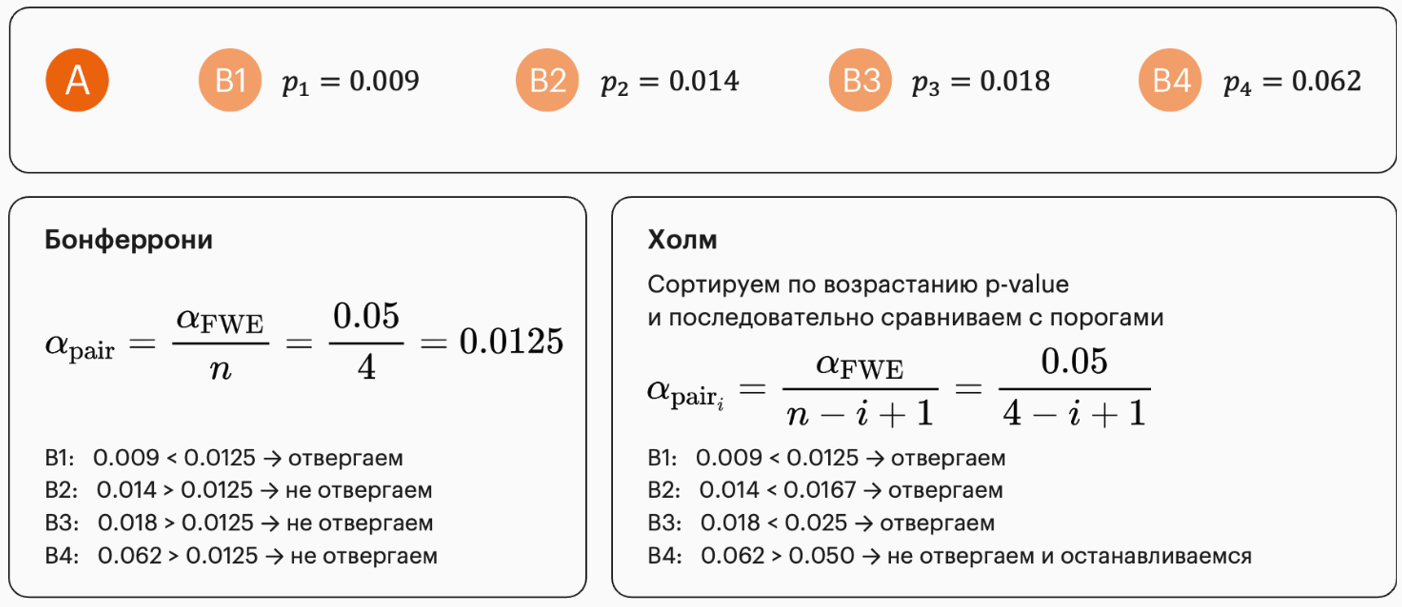

# ANOVA F-тест

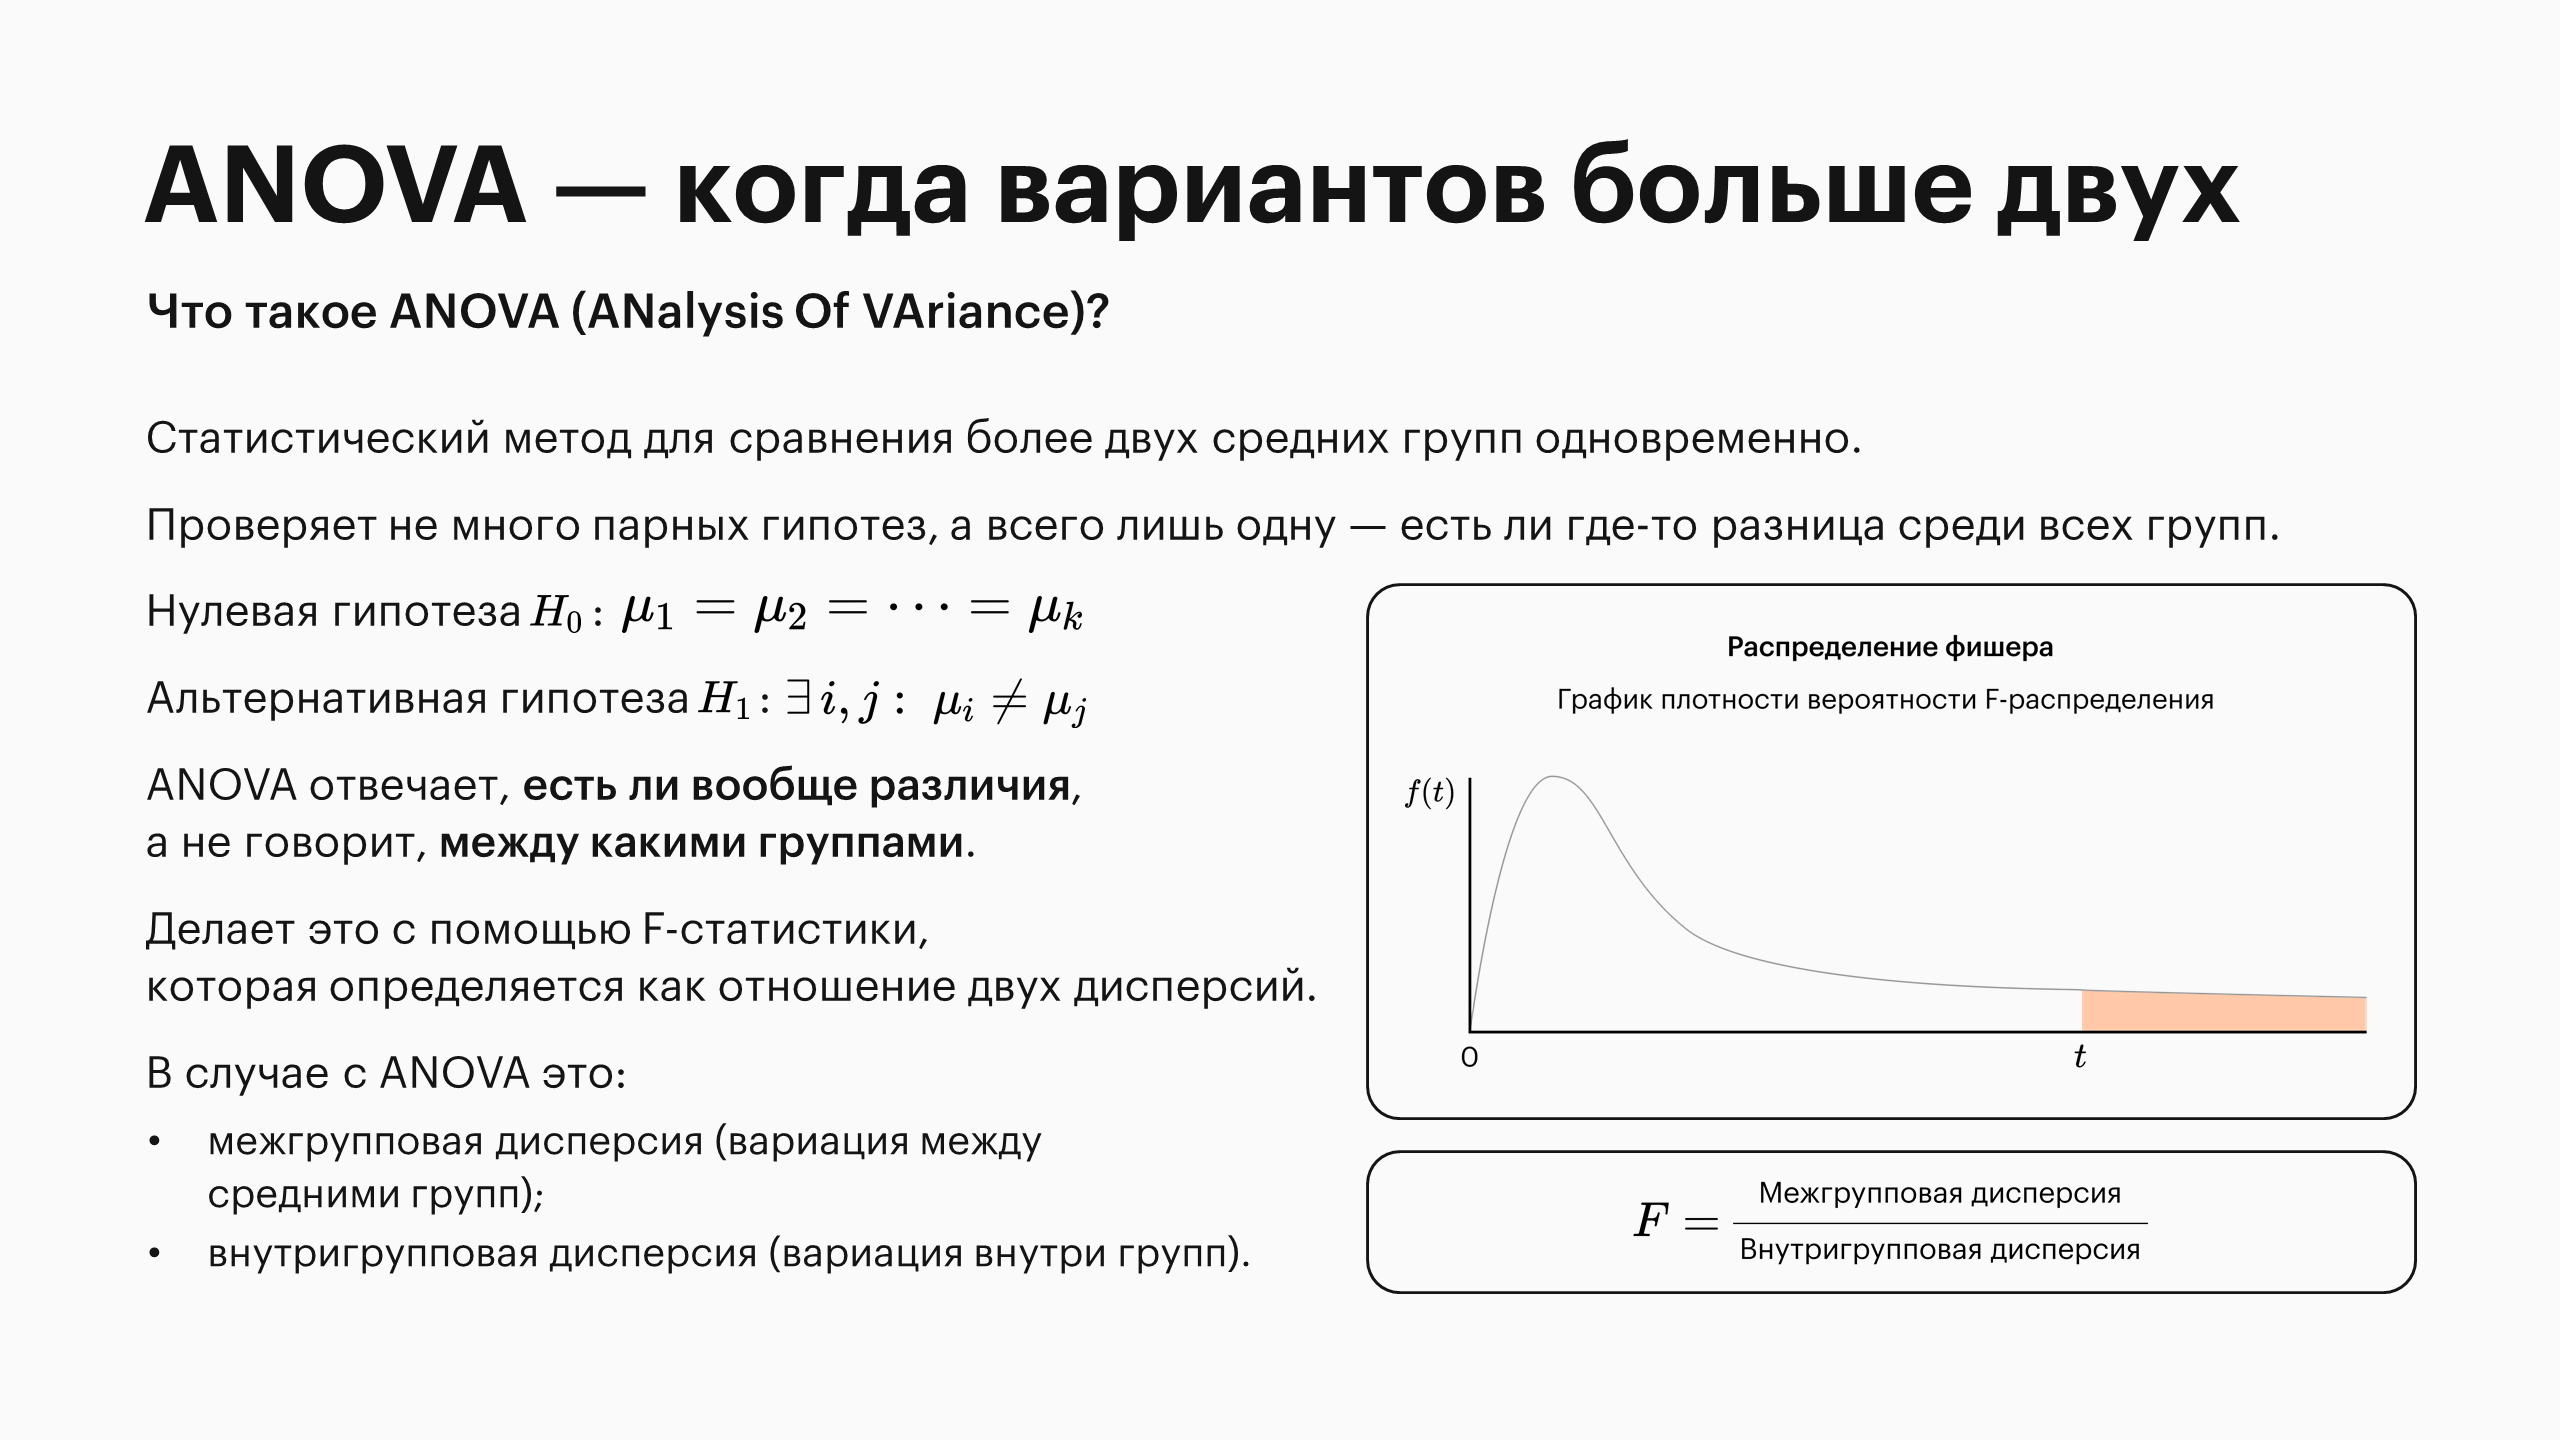

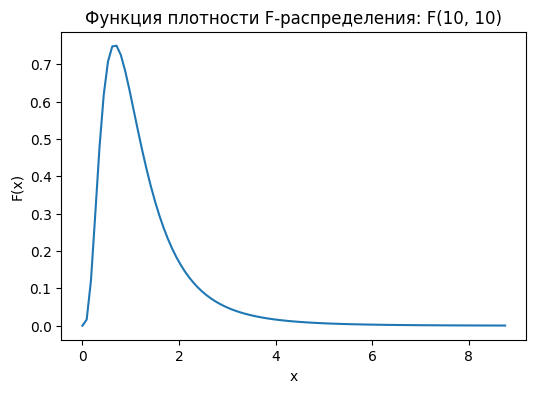

In [ ]:
dfn=10
dfd=10

x_max = stats.f.ppf(0.999, dfn, dfd)
x = np.linspace(0, x_max, 100)
y = stats.f.pdf(x, dfn, dfd)

plt.plot(x, y, label=f"CDF F({dfn}, {dfd})")
plt.xlabel("x")
plt.ylabel("F(x)")
_ = plt.title(f"Функция плотности F-распределения: F({dfn}, {dfd})")

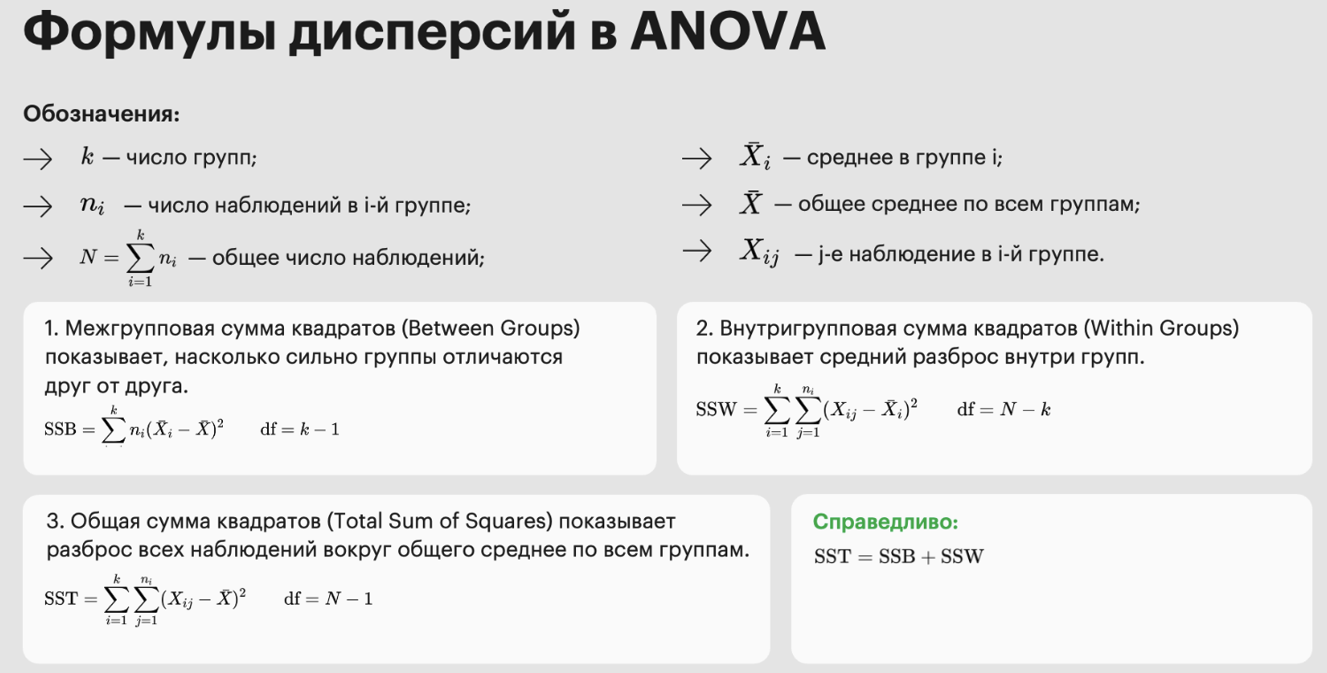

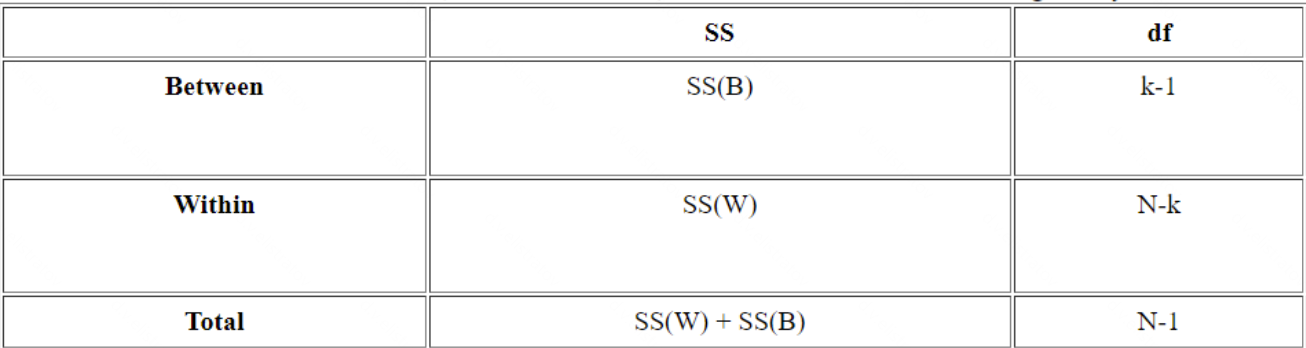

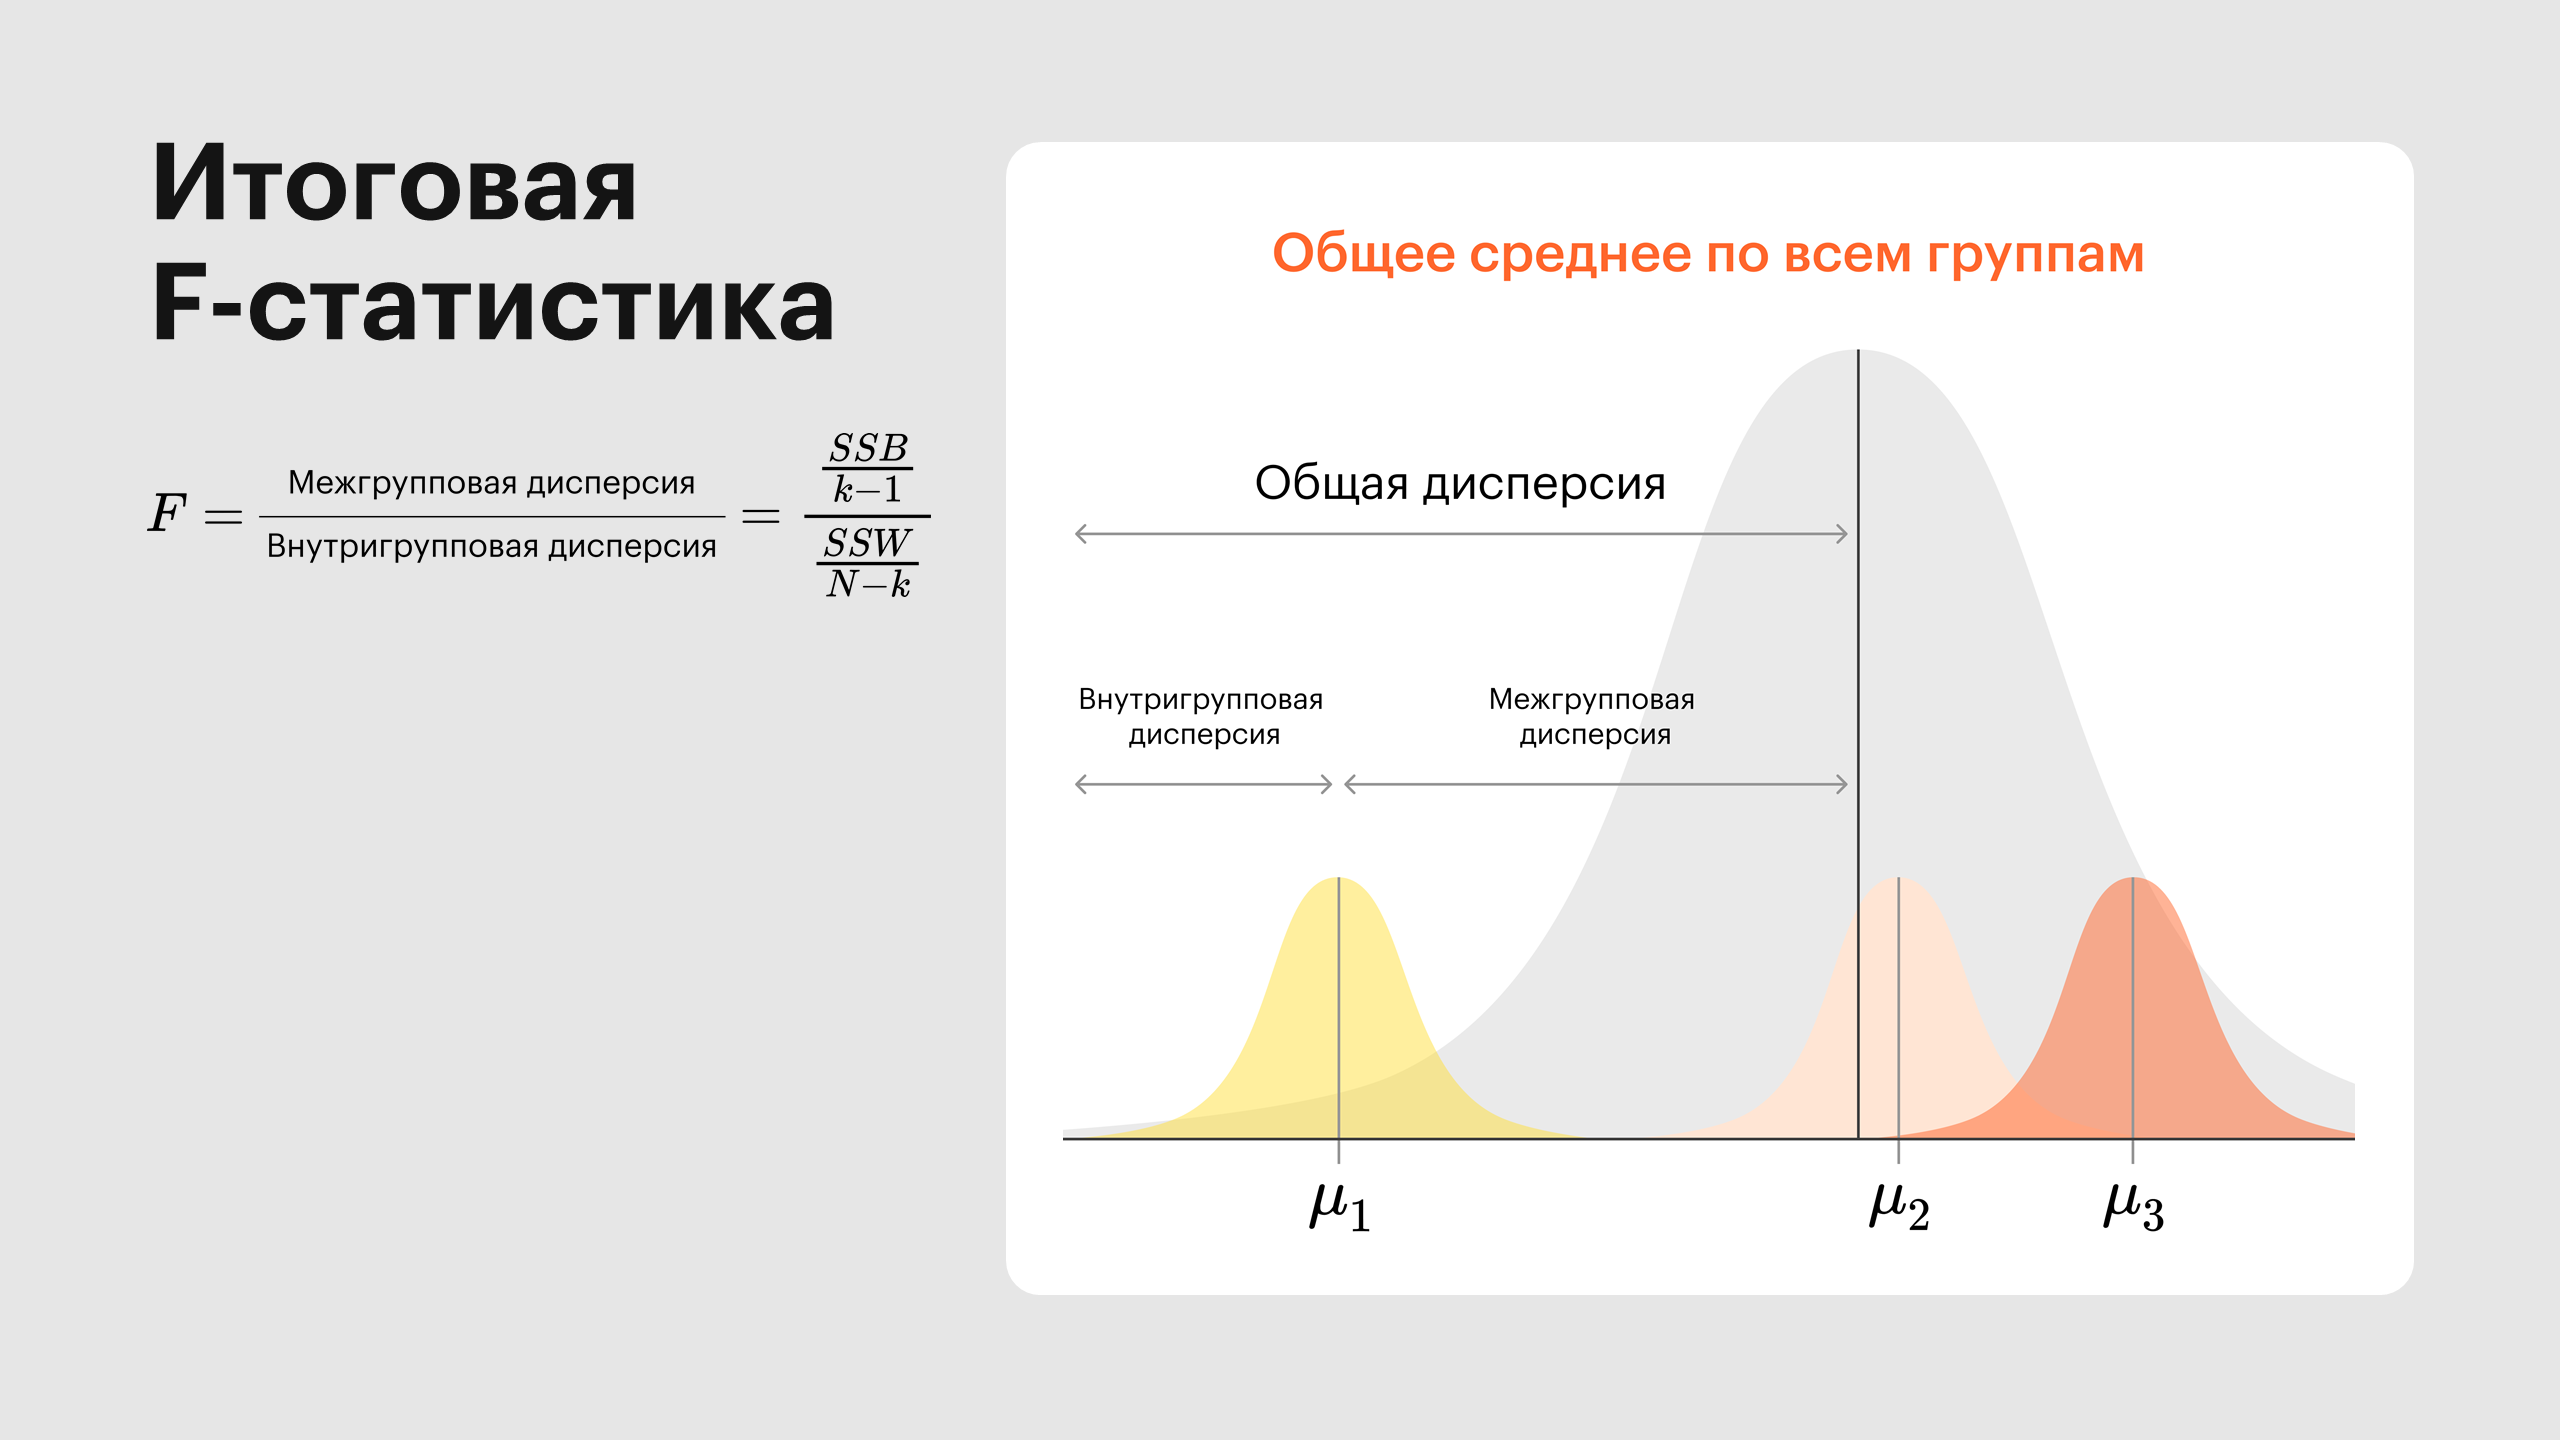

## Возможные кейсы

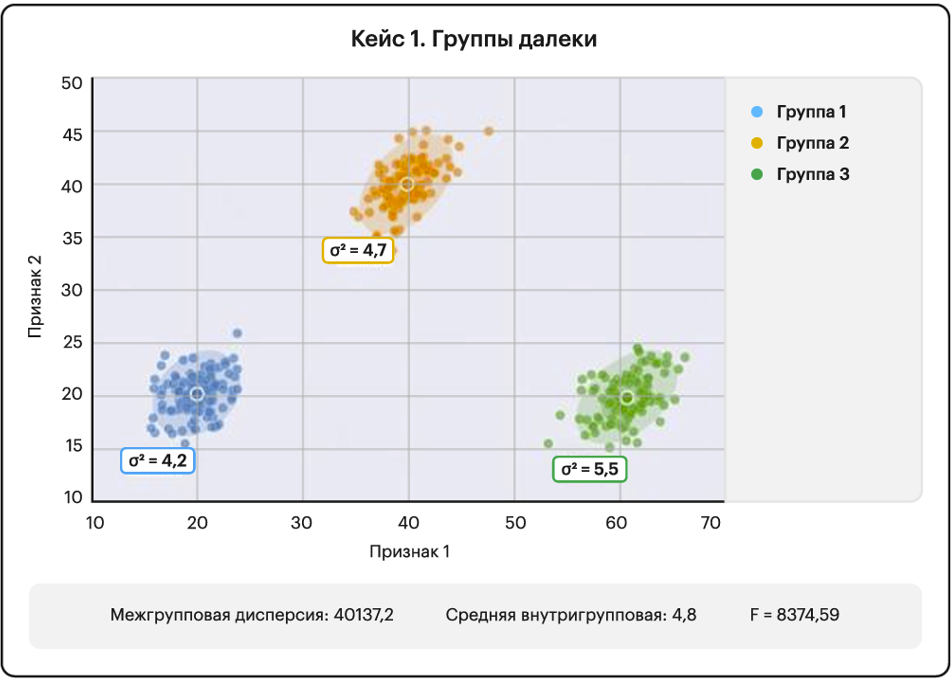

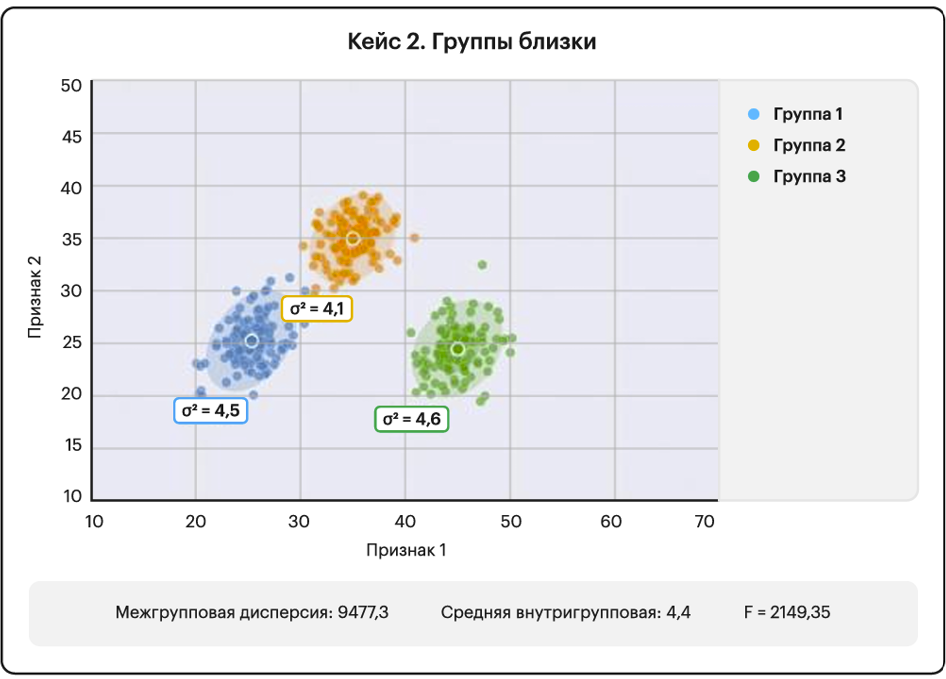

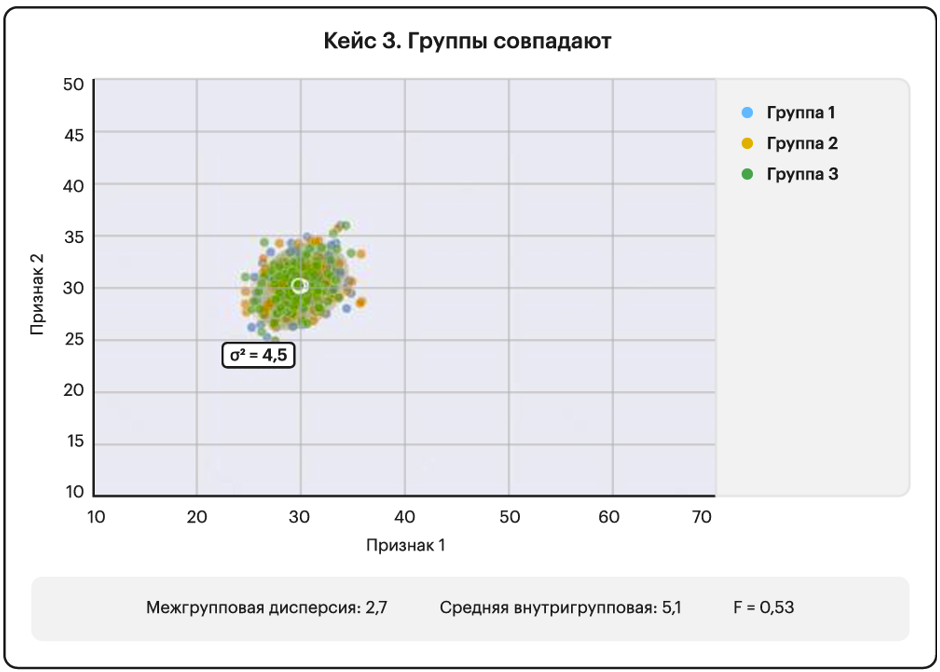

## Рассмотрим численный пример

Рассчитаем для примера значение F-статистики ручками.

In [ ]:
# Создадим 1000 наблюдений и распределим по 5 группам

num_groups = 5

x = np.random.rand(1000)
group_labels = np.random.randint(0, num_groups, size=len(x))

print(group_labels[:3])

[4 4 0]


In [ ]:
# Рассчитаем глобальное среднее
overall_mean = np.mean(x)

# А для каждой группы рассчитаем среднее и кол-во наблюдений
group_means = []
num_observes = []

for i in range(num_groups):
     group_means.append(np.mean(x[group_labels == i]))
     num_observes.append(len(x[group_labels == i]))


print(overall_mean)
print(group_means)
print(num_observes)

0.502021381321821
[np.float64(0.4805175013234595), np.float64(0.5270741015433169), np.float64(0.5166770970815848), np.float64(0.5161112251662224), np.float64(0.4703766577274993)]
[204, 188, 212, 199, 197]


In [ ]:
# Рассчитаем степени свободы within и between
df_between = num_groups - 1
df_within = len(x) - num_groups

print("Количество степеней свободы межгрупповой дисперсии = ", df_between)
print("Количество степеней свободы межгрупповой дисперсии = ", df_within)

Количество степеней свободы межгрупповой дисперсии =  4
Количество степеней свободы межгрупповой дисперсии =  995


In [ ]:
# Sum of Squares Between
SSB = np.sum([num_observes[i] * (group_means[i] - overall_mean)**2 for i in range(num_groups)])

# Mean square between groups
MSB = SSB / df_between

In [ ]:
# Sum of Squares Within
SSW = 0
for i in range(num_groups):
    group_samples = x[group_labels == i]
    SSW += np.sum((group_samples - group_means[i])**2)

# Mean square within groups
MSW = SSW / df_within

In [ ]:
# Значение статистического критерия F

F_value = MSB / MSW

print("F-value:", F_value)

F-value: 1.4531912967911842


In [ ]:
alpha = 0.05

f_critical = stats.f.ppf(1 - alpha, df_between, df_within)

print("Расчётное значение F-статистики:", F_value)
print("Пороговое значение F:", f_critical)

if F_value > f_critical:
    print("Нулевая гипотеза отвергается. В выборках есть различия")
else:
    print("Нулевая гипотеза не отвергается. В выборках нет различий")

Расчётное значение F-статистики: 1.4531912967911842
Пороговое значение F: 2.3808758069291818
Нулевая гипотеза не отвергается. В выборках нет различий


Рассчитаем встроенным методом из статпакета `f_oneway`.

In [ ]:
alpha = 0.05

f_value, p_value = stats.f_oneway(*[x[group_labels == i] for i in range(num_groups)])

print("F-value:", f_value)
print("p-value:", p_value)


# Check the hypothesis
if p_value < alpha:
    print("Нулевая гипотеза отвергается. В выборках есть различия")
else:
    print("Нулевая гипотеза не отвергается. В выборках нет различий")

F-value: 1.453191296791183
p-value: 0.21445725732312346
Нулевая гипотеза не отвергается. В выборках нет различий


**Вывод**

ANOVA F-тест может лишь показать, есть ли среди тестируемых групп хотя бы одна пара со статистически значимым разлличием. Данный тест не говорит нам, какая именно группа оторвалась от остальных и сколько таких групп есть.

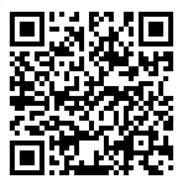